# **US Accidents - Exploratory Data Analysis Project**
Created by Guy Zamir & Tomer Rotman

## Libraries and File Path Configuration

In [ ]:
!pip install astral
!pip install timezonefinder

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 54.3/54.3 MB 9.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.1/1.1 MB 55.5 MB/s eta 0:00:00


In [ ]:
from google.colab import drive
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re
from astral import LocationInfo
from astral.sun import sun
from timezonefinder import TimezoneFinder
import pytz

tf = TimezoneFinder()

In [ ]:
drive.mount('/content/drive')

Mounted at /content/drive


**Important:** The dataset should be downloaded from [Kaggle](https://www.kaggle.com/datasets/sobhanmoosavi/us-accidents). Due to its size, this dataset cannot be temporarily uploaded to Colab's storage. Instead, it must be permanently uploaded to Google Drive. Change the values for `DATASET_FOLDER` and `DATASET_FILE_NAME` below when using a different folder or file.

In [ ]:
DATASET_FOLDER = '/content/drive/MyDrive/Data Analysis Project/'

In [ ]:
DATASET_FILE_NAME = 'US_Accidents.csv'

In [ ]:
FILE_PATH = DATASET_FOLDER + DATASET_FILE_NAME # Path to CSV file in Google Drive

##Introduction

This dataset contains traffic accident records across states of the USA. The data was continously collected from APIs that broadcast traffic events, captured by a massive network of sources including:

*   US and State Departments of Transportation
*   Law Enforcement Agencies
*   Traffic Cameras
*   Road Sensors

To make the dataset richer, exact locations of the accidents were paired with historical weather data. Additionally, the locations were mapped against street-level data. This enabled tagging of each accident with boolean indicators for the presence of traffic light, junction, stop sign and more.

Due to the large file size, we will initially examine only a preview of the dataset, as loading the entire file exceeds the RAM limitations of Google Colab.

In [ ]:
# Count rows without loading the full file
with open(FILE_PATH, 'r') as f:
    num_rows = sum(1 for _ in f) - 1  # subtract 1 for the header row

# Read only the header row to get the column count
num_cols = len(pd.read_csv(FILE_PATH, nrows=0).columns)

print(f"Dataset Shape: ({num_rows:,} x {num_cols})")

Dataset Shape: (7,728,394 x 46)


The dataset contains **7,728,394 rows** spread across **46 columns** - a scale large enough to surface meaningful insights.

In [ ]:
preview_df = pd.read_csv(FILE_PATH, nrows = 3)

In [ ]:
preview_df.head().T

,0,1,2
ID,A-1,A-2,A-3
Source,Source2,Source2,Source2
Severity,3,2,2
Start_Time,2016-02-08 05:46:00,2016-02-08 06:07:59,2016-02-08 06:49:27
End_Time,2016-02-08 11:00:00,2016-02-08 06:37:59,2016-02-08 07:19:27
Start_Lat,39.865147,39.928059,39.063148
Start_Lng,-84.058723,-82.831184,-84.032608
End_Lat,NaN,NaN,NaN
End_Lng,NaN,NaN,NaN
Distance(mi),0.01,0.01,0.01


In [ ]:
del preview_df  # Free RAM before loading the full dataset

Based on the dataset preview, we can confidently verify the purpose and contents of each column. The dataset includes the following variables:

| Variable | Description |
| :--- | :--- |
| `ID` | Unique identifier for each accident record |
| `Source` | The API that reported the event |
| `Severity` | The impact of the accident on traffic (scale of 1-4) |
| `Start_Time` | When the accident happened |
| `End_Time` | When the accident impact ended |
| `Start_Lat` | GPS latitude of the crash site |
| `Start_Lng` | GPS longitude of the crash site |
| `End_Lat` | GPS latitude marking the tail end of the resulting traffic jam |
| `End_Lng` | GPS longitude marking the tail end of the resulting traffic jam |
| `Distance(mi)` | The length of the road segment affected by the accident |
| `Description` | A human provided description of the accident |
| `Street` | Street name of accident |
| `City` | City of accident |
| `County` | County of the accident |
| `State` | State of the accident |
| `Zipcode` | Zipcode of the accident |
| `Country` | Country of the accident |
| `Timezone` | Timezone based on the location |
| `Airport_Code` | Denotes an airport-based weather station which is the closest one to location of the accident |
| `Weather_Timestamp` | Time the weather was recorded |
| `Temperature(F)` | Temperature in Fahrenheit |
| `Wind_Chill(F)` | Wind chill in Fahrenheit |
| `Humidity(%)` | Humidity in percentage |
| `Pressure(in)` | Air pressure in inches |
| `Visibility(mi)` | Visibility distance in miles |
| `Wind_Direction` | Wind direction |
| `Wind_speed(mph)` | Wind speed in mph |
| `Precipitation(in)` | Amount of rain or snow in inches |
| `Weather_Condition` | Text description of weather condition |
| `Amenity` | Near a restaurant, library, etc. |
| `Bump` | Near a speed bump |
| `Crossing` | Near a pedestrian crossing |
| `Give_Way` | Near a yield sign |
| `Junction` | Near a junction |
| `No_Exit` | Near a dead-end street |
| `Railway` | Near a railroad track |
| `Roundabout` | Near a circular junction |
| `Station` | Near a public transport station |
| `Stop` | Near a stop sign |
| `Traffic_Calming` | Near speed bump or chicanes |
| `Traffic_Signal` | Near a traffic light |
| `Turning_Loop` | Near a widened area for turning around |
| `Sunrise_Sunset` | Indicates whether the sun is physically above or below the horizon |
| `Civil_Twilight` | Indicates whether there is enough ambient sunlight to see the road without headlights |
| `Nautical_Twilight` | Indicates whether the sky has darkened to the point where the horizon is barely visible |
| `Astronomical_Twilight` | Indicates whether the sky has reached absolute, pitch-black darkness |

In this analysis we would like to answer the following questions:

- **How serious is the road accident problem in the US, and which regions are most affected?**
- **Can accident patterns reveal underlying safety issues and guide smarter deployment of emergency services?**
- **Can accident hotspots reveal infrastructure failures that put drivers at risk?**
- **Where should accident prevention efforts be focused?**

##Data Loading

### Variables Selection

In this step, we filter the dataset to include only the variables relevant to our analysis. We keep columns that provide meaningful insights (✅) and drop the rest (❌). This selective pruning achieves two key objectives: it kickstarts our data cleaning process and drastically reduces the memory footprint, allowing us to load and process this massive dataset smoothly in our current environment.

| Variable | ❌ / ✅ | Reason |
| :--- | :--- | :--- |
| `ID` | ❌ | Tells us nothing about the accident itself |
| `Source` | ❌ | We care about what happened, not which system reported it |
| `Severity` | ✅ | Allows to understand which conditions, times and locations produce the most distruptive ones |
| `Start_Time` | ✅ | Essential for understanding when accidents are most likely to occur |
| `End_Time` | ❌ | How long the traffic jam lasted is not a focus of this analysis |
| `Start_Lat` | ✅ | Helpful to identify dangerous locations |
| `Start_Lng` | ✅ | Helpful to identify dangerous locations |
| `End_Lat` | ❌ | Marks where the traffic ended, not where the accident happened |
| `End_Lng` | ❌ | Marks where the traffic ended, not where the accident happened |
| `Distance(mi)` | ❌ | How far traffic jam stretched is not a focus of this analysis |
| `Description` | ❌ | Everything useful in it is already captured by the other columns in a cleaner, structured form |
| `Street` | ✅ | Lets us identify problematic streets |
| `City` | ✅ | Lets us identify problematic cities |
| `County` | ❌ | Comparing counties is not a focus in this analysis |
| `State` | ✅ | Lets us identify problematic states |
| `Zipcode` | ❌ | Redundant if State, City and Street are kept |
| `Country` | ❌ | Redundant since all accidents in the dataset happened in the US |
| `Timezone` | ❌ | Does not provide necessary information |
| `Airport_Code` | ❌ | Irrelevant to any accident |
| `Weather_Timestamp` | ❌ | Already have the accident time |
| `Temperature(F)` | ✅ | Retained to cross-validate `Weather_Condition` labels |
| `Wind_Chill(F)` | ❌ | Mathematically derived from `Temperature` and `Wind_Speed`, which are already kept. Adds no new cross-validation value |
| `Humidity(%)` | ✅ | Retained to cross-validate `Weather_Condition` labels |
| `Pressure(in)` | ❌ | Does not map intuitively to any specific weather condition label |
| `Visibility(mi)` | ✅ | Retained to cross-validate `Weather_Condition` labels |
| `Wind_Direction` | ❌ | Adds no new cross-validation value |
| `Wind_speed(mph)` | ✅ | Retained to cross-validate `Weather_Condition` labels |
| `Precipitation(in)` | ❌ | Time window of the measurement is unspecified, making it unreliable for cross-validation |
| `Weather_Condition` | ✅ | Lets us group accidents by weather type |
| `Amenity` | ❌ | No specific road-safety meaning |
| `Bump` | ✅ | Speed bumps directly affect how fast vehicles are moving at that spot |
| `Crossing` | ✅ | Risk point |
| `Give_Way` | ✅ | Risk point |
| `Junction` | ✅ | Risk point |
| `No_Exit` | ❌ | Probably will not tell us anything meaningful |
| `Railway` | ✅ | Risk point |
| `Roundabout` | ✅ | Risk point |
| `Station` | ✅ | Bus and train stations bring more foot traffic and slower-moving vehicles to an area |
| `Stop` | ✅ | Risk point |
| `Traffic_Calming` | ❌ | Essentially the same information already captured by the `Bump` column |
| `Traffic_Signal` | ✅ | Risk point |
| `Turning_Loop` | ❌ | Unlikely to reveal any meaningful pattern |
| `Sunrise_Sunset` | ❌ | Dropped in favor of `Civil_Twilight`, which is a better functional indicator of when headlights are actually required |
| `Civil_Twilight` | ✅ | Provides metric for driver visibility |
| `Nautical_Twilight` | ❌ | Dropped in favor of `Civil_Twilight`, which is a better functional indicator of when headlights are actually required |
| `Astronomical_Twilight` | ❌ | Dropped in favor of `Civil_Twilight`, which is a better functional indicator of when headlights are actually required |

In [ ]:
KEEP_COLS = [
    'Severity', 'Start_Time', 'Start_Lat', 'Start_Lng',
    'Street', 'City', 'State',
    'Temperature(F)', 'Humidity(%)', 'Visibility(mi)',
    'Wind_Speed(mph)', 'Weather_Condition',
    'Bump', 'Crossing', 'Give_Way', 'Junction', 'Railway',
    'Roundabout', 'Station', 'Stop', 'Traffic_Signal',
    'Civil_Twilight'
]

In [ ]:
df = pd.read_csv(FILE_PATH, usecols = KEEP_COLS)
df['Start_Time'] = pd.to_datetime(df['Start_Time'], format = 'mixed') # Confidently converted based on the preview

### Duplicates Removal

In [ ]:
df.duplicated().sum() # Count duplicates

np.int64(487992)

There are 487,992 duplicated rows in the dataset. Initially, the assumption was that these duplicates originated from the same accident being reported by multiple sources. However, upon inspection, the duplicate records were found to come from the same source - suggesting a data collection bug where the API logged the same event twice. It is also worth noting that these duplicates only surfaced due to the fact we dropped the `ID` column, which assigns a unique identifier to every row and would otherwise mask any duplicates entirely. Below are a few examples:

In [ ]:
duplicate_rows = df[df.duplicated(keep = False)]
duplicate_rows.sort_values(by = KEEP_COLS).head(10)

,Severity,Start_Time,Start_Lat,Start_Lng,Street,City,State,Temperature(F),Humidity(%),Visibility(mi),...,Bump,Crossing,Give_Way,Junction,Railway,Roundabout,Station,Stop,Traffic_Signal,Civil_Twilight
2713362,1,2018-07-25 19:38:21,26.272926,-80.296432,Sawgrass Expy,Pompano Beach,FL,84.0,76.0,10.0,...,False,False,False,False,False,False,False,False,False,Day
2713363,1,2018-07-25 19:38:21,26.272926,-80.296432,Sawgrass Expy,Pompano Beach,FL,84.0,76.0,10.0,...,False,False,False,False,False,False,False,False,False,Day
7219431,1,2020-02-19 14:27:00,35.860980,-78.814390,I-40 E,Morrisville,NC,49.0,69.0,10.0,...,False,False,False,False,False,False,False,False,False,Day
7219432,1,2020-02-19 14:27:00,35.860980,-78.814390,I-40 E,Morrisville,NC,49.0,69.0,10.0,...,False,False,False,False,False,False,False,False,False,Day
7228129,1,2020-02-27 10:36:00,36.060660,-80.010620,Sandy Ridge Rd,Colfax,NC,41.0,38.0,10.0,...,False,False,False,False,False,False,False,False,False,Day
7228130,1,2020-02-27 10:36:00,36.060660,-80.010620,Sandy Ridge Rd,Colfax,NC,41.0,38.0,10.0,...,False,False,False,False,False,False,False,False,False,Day
7228829,1,2020-02-28 08:46:00,35.534600,-82.601350,Brevard Rd,Asheville,NC,32.0,61.0,9.0,...,False,False,False,False,False,False,False,False,True,Day
7228830,1,2020-02-28 08:46:00,35.534600,-82.601350,Brevard Rd,Asheville,NC,32.0,61.0,9.0,...,False,False,False,False,False,False,False,False,True,Day
7228842,1,2020-02-28 15:32:00,35.509190,-82.575070,I-26 W,Asheville,NC,45.0,48.0,9.0,...,False,False,False,False,False,False,False,False,False,Day
7228843,1,2020-02-28 15:32:00,35.509190,-82.575070,I-26 W,Asheville,NC,45.0,48.0,9.0,...,False,False,False,False,False,False,False,False,False,Day


In [ ]:
df.drop_duplicates(inplace = True) # Keep first occurence, remove the rest

In [ ]:
df.duplicated().sum() # Verify that duplicates have been removed

np.int64(0)

## Data Assessment

The next step is to explore the dataset in order to improve column naming where necessary and optimize the types, as well as to examine the existing values, their distributions, and the value ranges across different variables, in order to find potential data quality issues, such as outliers, invalid or impossible values and missing data.

In [ ]:
df.shape

(7240402, 22)

This means there are 7,240,402 accident records.

In [ ]:
df.describe(include='all').T

,count,unique,top,freq,mean,min,25%,50%,75%,max,std
Severity,7240402.0,NaN,NaN,NaN,2.223994,1.0,2.0,2.0,2.0,4.0,0.496262
Start_Time,7240402,NaN,NaN,NaN,2020-05-04 08:02:51.827541248,2016-01-14 20:18:33,2018-10-14 15:49:23.249999872,2020-09-29 12:43:30,2021-12-28 17:43:00,2023-03-31 23:30:00,NaN
Start_Lat,7240402.0,NaN,NaN,NaN,36.231344,24.5548,33.434952,35.817329,40.071769,49.002201,5.030217
Start_Lng,7240402.0,NaN,NaN,NaN,-94.78545,-124.623833,-117.218199,-87.9132,-80.40071,-67.113167,17.340815
Street,7230798,336306,I-95 N,74594,NaN,NaN,NaN,NaN,NaN,NaN,NaN
City,7240165,13678,Houston,163346,NaN,NaN,NaN,NaN,NaN,NaN,NaN
State,7240402,49,CA,1630336,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Temperature(F),7088273.0,NaN,NaN,NaN,61.698595,-89.0,49.0,64.0,76.0,207.0,18.99854
Humidity(%),7078751.0,NaN,NaN,NaN,64.94177,1.0,48.0,67.0,84.0,100.0,22.808223
Visibility(mi),7075669.0,NaN,NaN,NaN,9.090608,0.0,10.0,10.0,10.0,140.0,2.697773


Several observations are immediately visible from the summary above:

---

1.   **Time Range Observation**
      
**`Start_Time`** spans from January 14, 2016 to March 31, 2023. Two boundary considerations are worth noting:

*   2023 is incomplete, covering only the first three months of the year. Including it in any year-over-year trend analysis would produce a misleading drop and should therefore be excluded from such comparisons.
*   2016 begins mid-January rather than January 1st. Given that only a few weeks are missing, this is negligible and 2016 will be treated as a full year in trend analysis.

---

2.   **Column Naming**

Several column names do not accurately reflect their content. Therefore, name changes are needed:

*   **`Severity`** → **`Traffic_Impact`** — the column does not measure how severe the accident itself was, but rather how severely it disrupted traffic flow, making the original name misleading.
*   **`Start_Time`** → **`Datetime`** - "Start" implies a duration. This column simply records when the accident occurred.
*   **`Start_Lat`** & **`Start_Lng`** → **`Latitude`** & **`Longitude`** - the "Start" prefix is redundant since the end coordinates were dropped.
*   **`Street`** → **`Road`** - the column contains a mix of street names and highway designations such as "I-95 N", making "Road" a more accurate label.
*   `Civil_Twilight` → `Is_Day` - the column contains only two values, Day and Night, which can be from `bool` type, and the term Civil Twilight is not immediately intuitive to someone unfamiliar with the dataset.

---

3.   **Readability**

**`State`** stores values as two-letter abbreviation (e.g, "CA" for California). Therefore, full state names will be needed for readability in visualizations. A mapping dictionary will be maintained for this purpose.

---

4.   **Missing Values Detected**

Out of 7,240,402 accident records, several columns clearly contain missing values.

---

5.   **Outliers Detected**  

*   **`Temperature(F)`** ranges from -89°F to 207°F. The coldest temperature ever recorded in the contiguous US is around -70°F, and the hottest is 134°F.
*   **`Wind_Speed(mph)`** has a maximum of 1,087 mph. While a severe hurricane or a tornado can produce wind gusts exceeding 100 mph, people do not drive during those conditions, and roads are typically closed.

---

In [ ]:
df.info(show_counts = True)

<class 'pandas.core.frame.DataFrame'>
Index: 7240402 entries, 0 to 7728393
Data columns (total 22 columns):
 #   Column             Non-Null Count    Dtype         
---  ------             --------------    -----         
 0   Severity           7240402 non-null  int64         
 1   Start_Time         7240402 non-null  datetime64[ns]
 2   Start_Lat          7240402 non-null  float64       
 3   Start_Lng          7240402 non-null  float64       
 4   Street             7230798 non-null  object        
 5   City               7240165 non-null  object        
 6   State              7240402 non-null  object        
 7   Temperature(F)     7088273 non-null  float64       
 8   Humidity(%)        7078751 non-null  float64       
 9   Visibility(mi)     7075669 non-null  float64       
 10  Wind_Speed(mph)    6684976 non-null  float64       
 11  Weather_Condition  7078766 non-null  object        
 12  Bump               7240402 non-null  bool          
 13  Crossing           7240402 non-n

From the type information above, we can also note that several columns require dtype optimization:

- **`Severity`** is stored as `int64` but has only 4 ordered values (1–4) - it should be an ordered categorical.
- **`Start_Lat`** and **`Start_Lng`** are `float64` but `float32` precision is more than sufficient for GPS coordinates.
- **`State`**, **`City`**, **`Weather_Condition`**, and **`Civil_Twilight`** are stored as generic `object` strings but have low enough cardinality to benefit from the `category` dtype.
- All weather numeric columns (**`Temperature`**, **`Humidity`**, **`Visibility`**, **`Wind_Speed`**, **`Precipitation`**) can be safely downcast from `float64` to `float32`. **`Civil_Twilight`**, as mentioned earlier, will be renamed to **`Is_Day`**, since it contains only two values - Day and Night, making `bool` the natural representation as it is more memory efficient.

---

### Missing Values

In [ ]:
# Keyword patterns that commonly represent missing or null values
_PLACEHOLDER_KEYWORDS = ['n/a', 'na', 'none', 'null', 'unknown', 'missing', 'undefined', 'nan', 'nil',
                          'not available', 'not applicable', 'no data', '--', '---', '?', '??',
                          'n.a.', 'n.a', 'tbd', 'tba']

# Symbol-only patterns that likely represent missing values (e.g. '-', '?', '#')
_PLACEHOLDER_SYMBOLS = ['#', '@', '!', '*', '/', '\\', '.', ',', '_', '|', '~', '^']

# Compiled once at module level for efficiency - matches keywords as whole words (not substrings)
_KEYWORD_PATTERN = re.compile(
    r'(^|\s)(' + '|'.join(re.escape(kw) for kw in _PLACEHOLDER_KEYWORDS) + r')(\s|$)'
)

# Compiled once - matches values that consist entirely of symbol characters
_SYMBOL_PATTERN = re.compile(r'^[' + re.escape(''.join(_PLACEHOLDER_SYMBOLS)) + r']+$')

In [ ]:
def detect_missing_placeholders(col):
    unique_values = df[col].dropna().unique() # Ignore actual NaNs - we only look for disguised ones
    suspicious = [
        str(v) for v in unique_values
        if _KEYWORD_PATTERN.search(str(v).strip().lower()) or _SYMBOL_PATTERN.match(str(v).strip())
    ]
    if suspicious:
        print(f'Suspicious placeholder(s) found in {col}: {suspicious}')
    else:
        print(f'No suspicious placeholders found in {col}')

In [ ]:
for col in df.select_dtypes(include='object').columns:
    if col == 'Civil_Twilight':  # Only 'Day' and 'Night' - missing values are actual NaNs according to the description table
          continue
    detect_missing_placeholders(col)

Suspicious placeholder(s) found in Street: ['Yorktown Apartments Access None', 'Virginia Center Commons Access None', 'Missing Link Rd', 'Nan Gray Davis Rd', 'Wilton Properties Apartments Access None', ' Nan St', ' Nan Ln', ' Null Add', 'Row Access None', 'Hollybrook Apartments Access None', 'Bremner Woods Apartments Access None', 'Unknown Soldier Dr', 'Resource Develpment Assoc Access None']
No suspicious placeholders found in City
No suspicious placeholders found in State
Suspicious placeholder(s) found in Weather_Condition: ['N/A Precipitation']


The function flagged several suspicious values across the string columns. In **`Weather_Condition`**, `N/A Precipitation` was identified as a placeholder for missing weather data. In **`Street`**, the value `Null Add` was identified as a placeholder for a missing address. All other flagged values were determined to be legitimate - real road names, transit route names, or apartment complex access roads. The word `None` appearing in some access road entries likely refers to the absence of a specific road name for that access point.

Both identified placeholders will be replaced with `NaN` in the cell below.

In [ ]:
n_weather = (df['Weather_Condition'] == 'N/A Precipitation').sum()
n_street = (df['Street'] == ' Null Add').sum()

df['Weather_Condition'] = df['Weather_Condition'].replace('N/A Precipitation', np.nan)
df['Street'] = df['Street'].replace('Null Add', np.nan)

print(f"Replaced {n_weather:,} 'N/A Precipitation' values in Weather_Condition with NaN")
print(f"Replaced {n_street:,} 'Null Add' values in Street with NaN")

Replaced 2,856 'N/A Precipitation' values in Weather_Condition with NaN
Replaced 1 'Null Add' values in Street with NaN


The function covers common placeholder patterns, but it cannot guarantee full detection since unusual placeholders may still be present. As an additional layer of inspection, we visually examine the value distributions for each string column below.

In [ ]:
def plot_value_counts_head(col, n=30):
    counts = df[col].value_counts(dropna=False)  # Include NaN in counts to make missing values visible
    values = counts.head(n) # Keep only the n most frequent values
    title = f'{col} — {n} Most Frequent Values ({df[col].nunique()} unique)'

    height = max(6, len(values) * 0.35) # Dynamic height based on number of bars
    fig, ax = plt.subplots(figsize=(12, height))
    values.plot(kind='barh', ax=ax)
    ax.set_title(title)
    ax.set_xlabel('Count')
    plt.tight_layout()
    plt.show()

In [ ]:
def plot_value_counts_tail(col, n=30):
    counts = df[col].value_counts(dropna=False) # Include NaN in counts to make missing values visible
    values = counts.tail(n) # Keep only the n least frequent values
    title = f'{col} — {n} Least Frequent Values ({df[col].nunique()} unique)'

    height = max(6, len(values) * 0.35) # Dynamic height based on number of bars
    fig, ax = plt.subplots(figsize=(12, height))
    values.plot(kind='barh', ax=ax)
    ax.set_title(title)
    ax.set_xlabel('Count')
    plt.tight_layout()
    plt.show()

In [ ]:
def plot_value_counts_all(col):
    counts = df[col].value_counts(dropna=False) # Include NaN in counts to make missing values visible
    title = f'{col} — All Values ({df[col].nunique()} unique)'

    height = max(6, len(counts) * 0.35) # Dynamic height based on number of bars
    fig, ax = plt.subplots(figsize=(12, height))
    counts.plot(kind='barh', ax=ax)
    ax.set_title(title)
    ax.set_xlabel('Count')
    plt.tight_layout()
    plt.show()

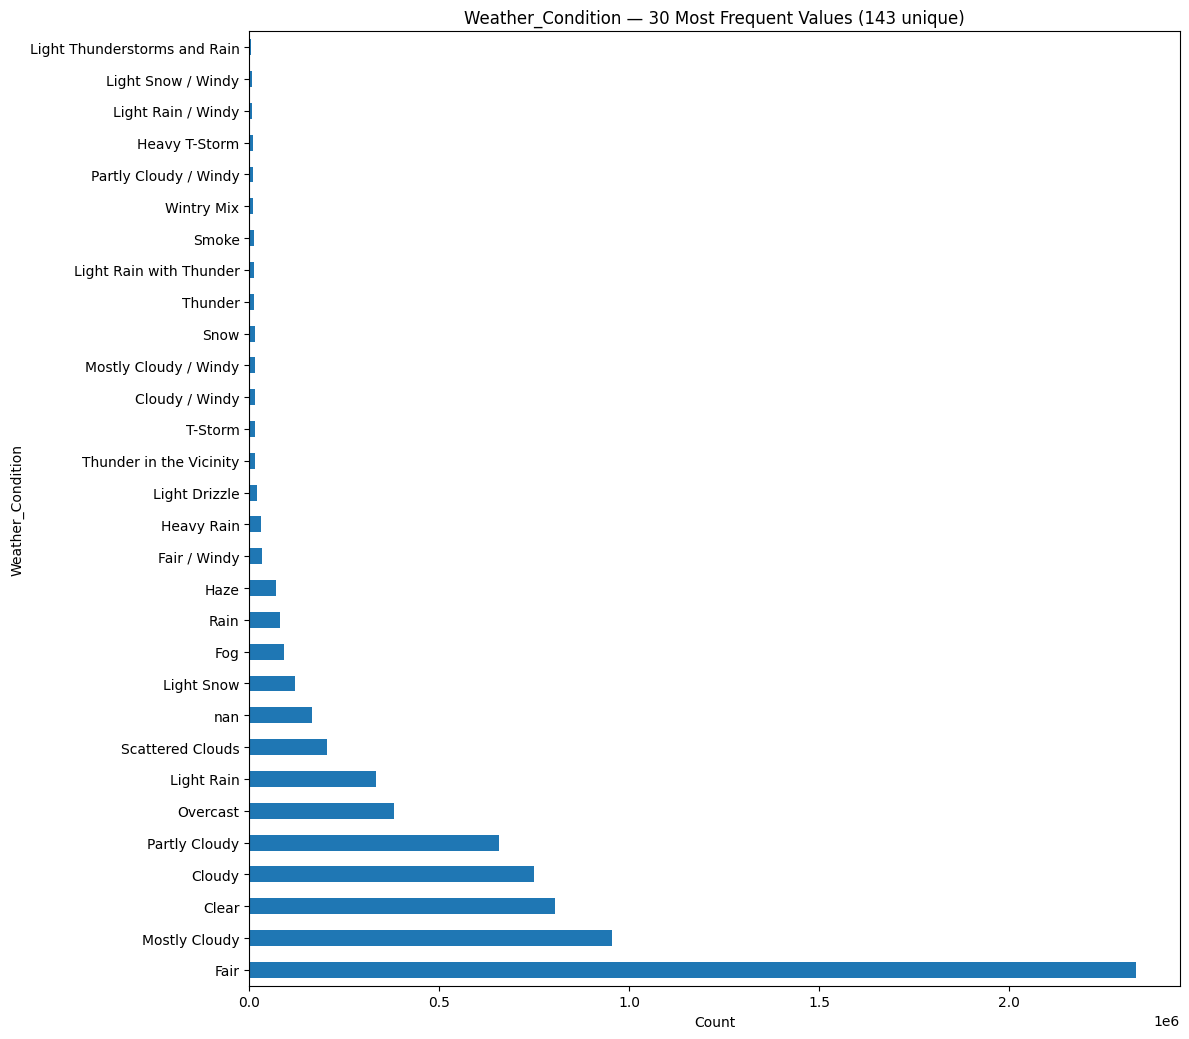

In [ ]:
plot_value_counts_head('Weather_Condition')

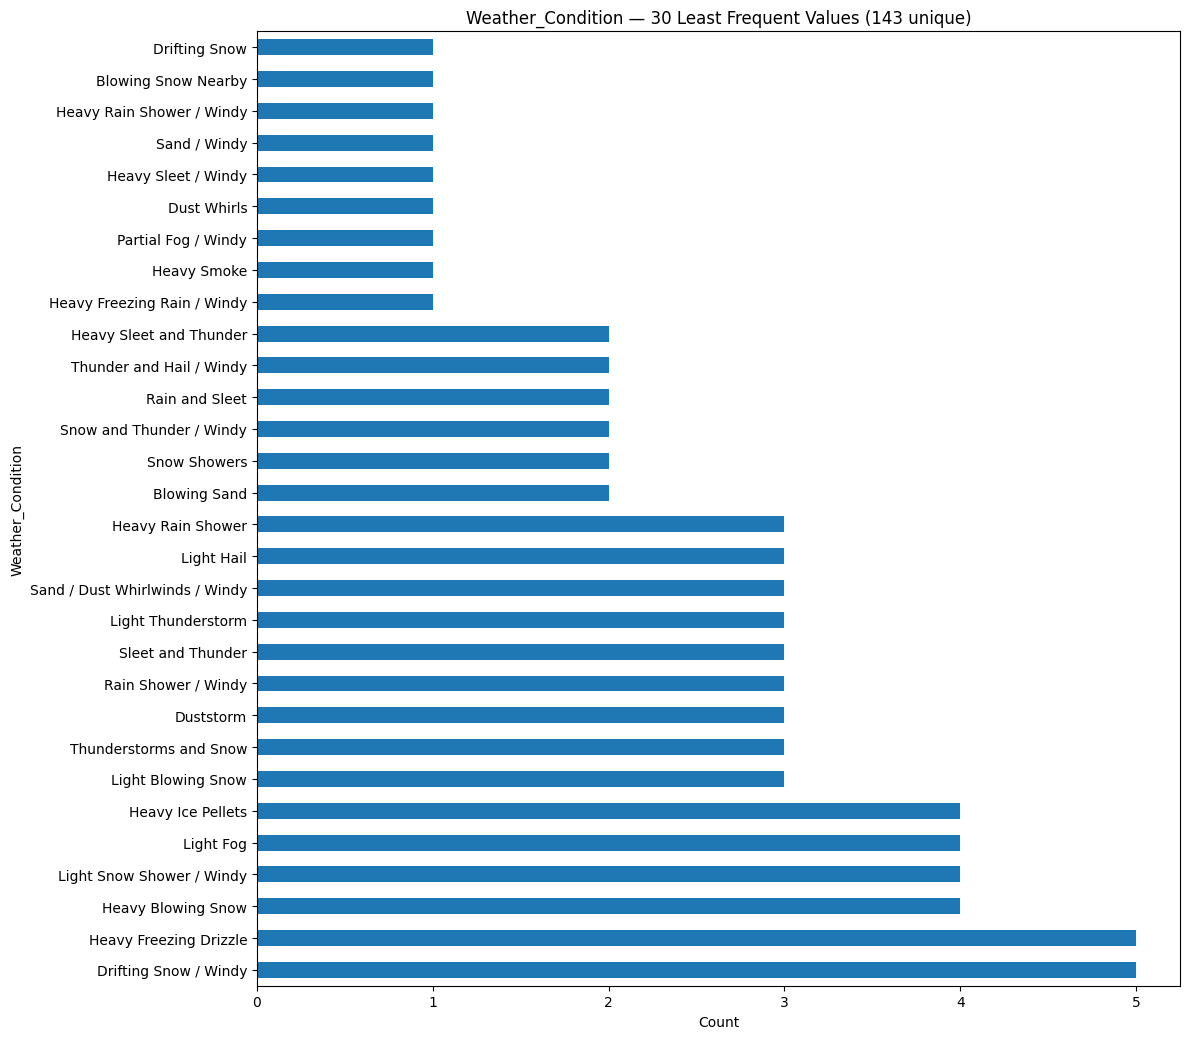

In [ ]:
plot_value_counts_tail('Weather_Condition')

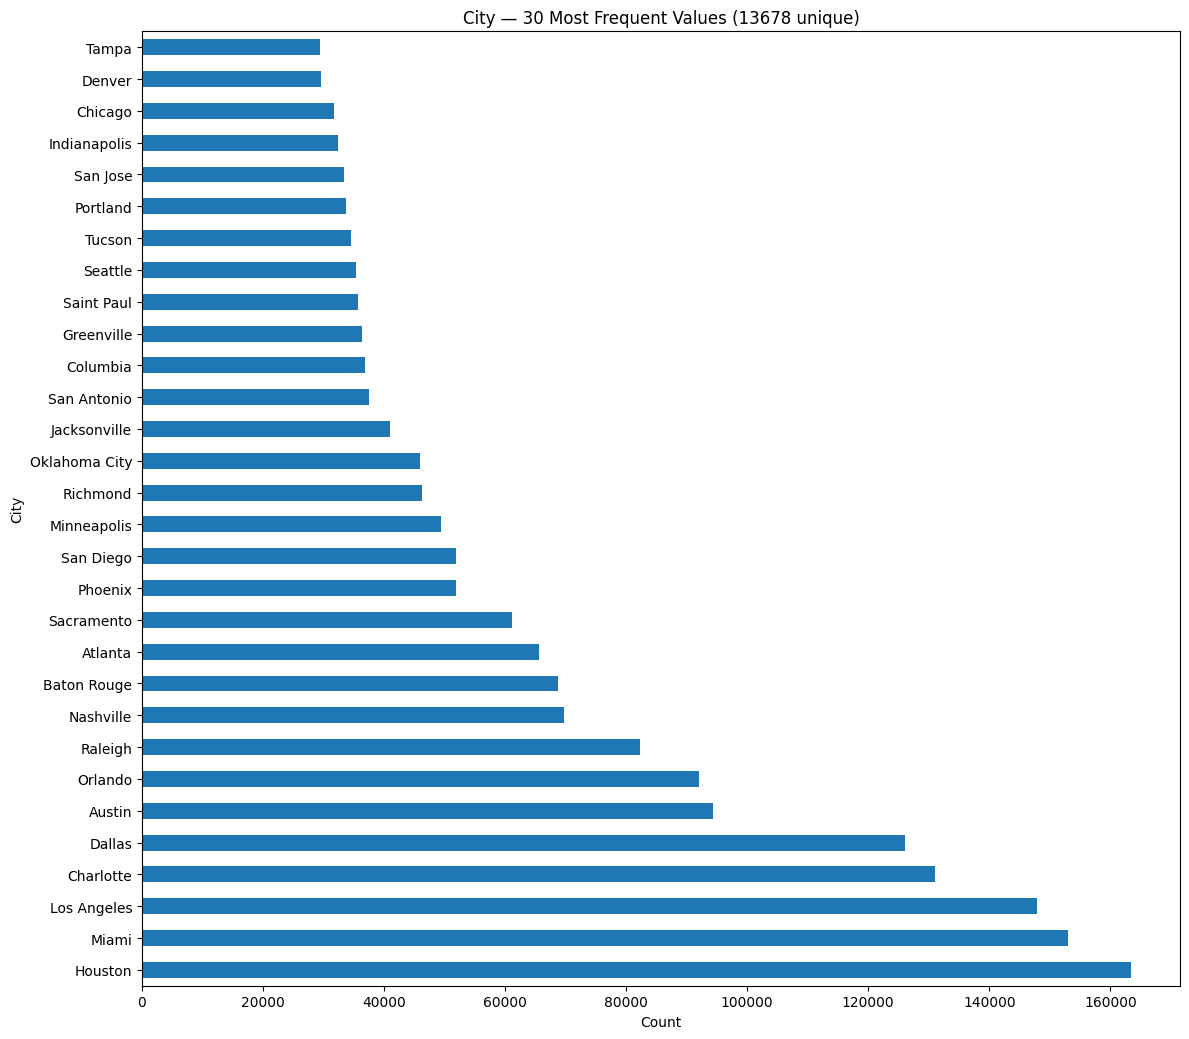

In [ ]:
plot_value_counts_head('City')

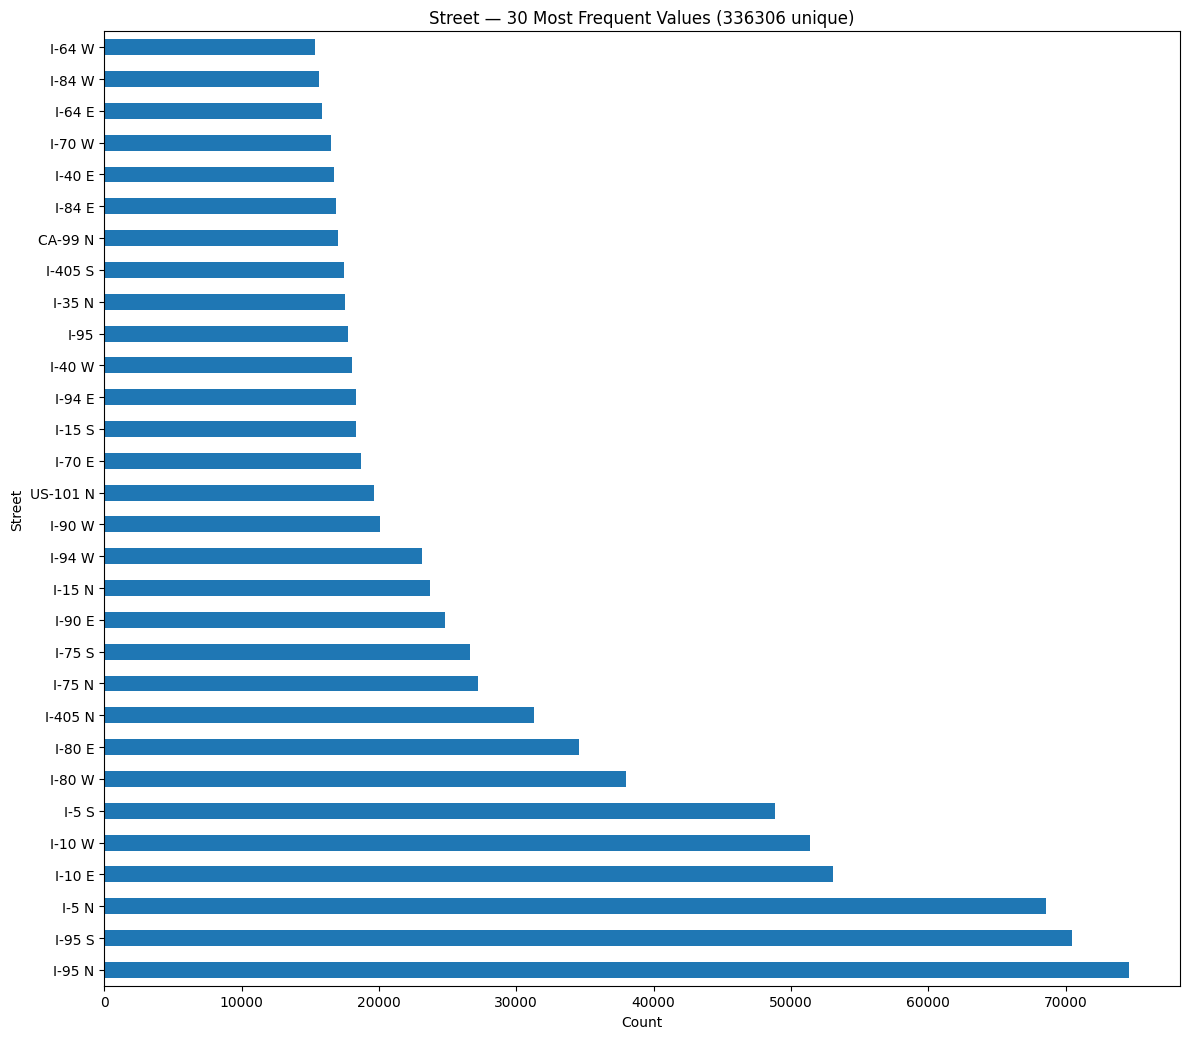

In [ ]:
plot_value_counts_head('Street')

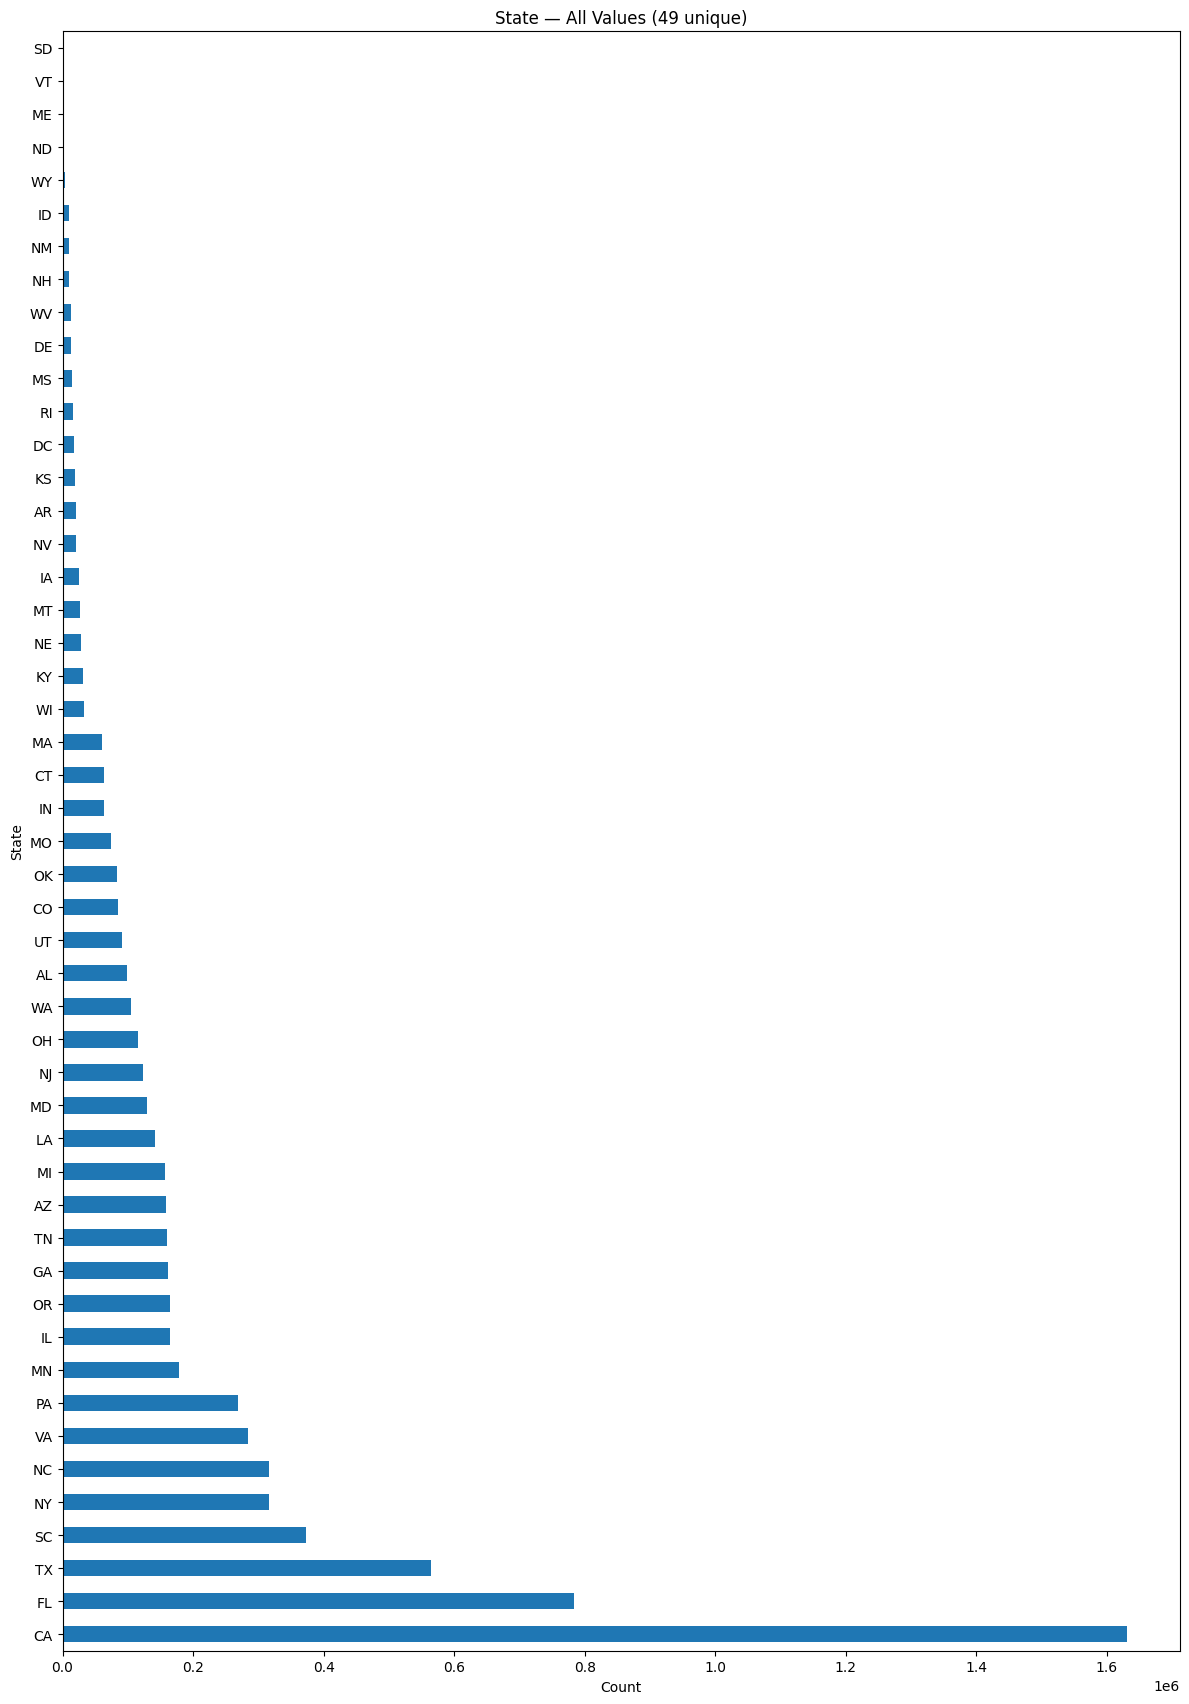

In [ ]:
plot_value_counts_all('State')

No other suspicious placeholders for missing values were found across any of the columns.

With the visual inspection complete, we can now calculate the actual missing value percentage for each variable:

In [ ]:
missing_count = df.isnull().sum().sort_values(ascending=False)
missing_count = missing_count[missing_count > 0] # Filter out the zeros
missing_percentage = (missing_count / len(df)) * 100

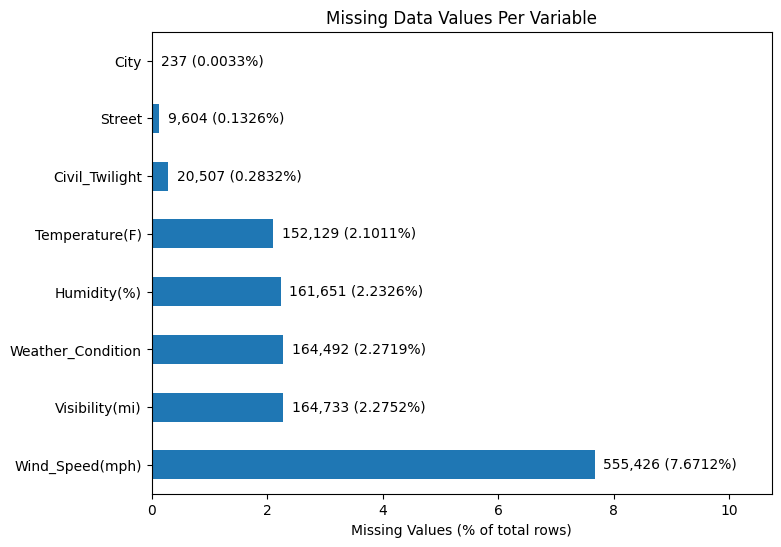

In [ ]:
ax = missing_percentage.plot(kind='barh', figsize=(8, 6))

for i, (count, pct) in enumerate(zip(missing_count, missing_percentage)):
    ax.text(pct + missing_percentage.max() * 0.02, i, f'{count:,} ({pct:.4f}%)', va='center')

plt.title('Missing Data Values Per Variable')
plt.xlabel('Missing Values (% of total rows)')
plt.xlim(0, missing_percentage.max() * 1.4)  # Extra space for the labels

plt.show()

**`City`** and **`Street`** are missing for a negligible portion of rows, therefore not critical for the analysis. For the numerical columns and **`Weather_Condition`**, the missing percentage will probably increase after outlier removal - however, these columns are not directly used in the analysis, they are only cross-validate weather condition labels. Rows where too many values were removed will be flagged as having unknown weather conditions. **`Civil_Twilight`** missing values will be fully filled using the astral library. While a simple time-based rule (e.g. 6am-6pm = day) could approximate day and night, astral calculates sunrise and sunset times based on the exact coordinates and timestamp of each accident, making it a more precise approach.

### Data Validity

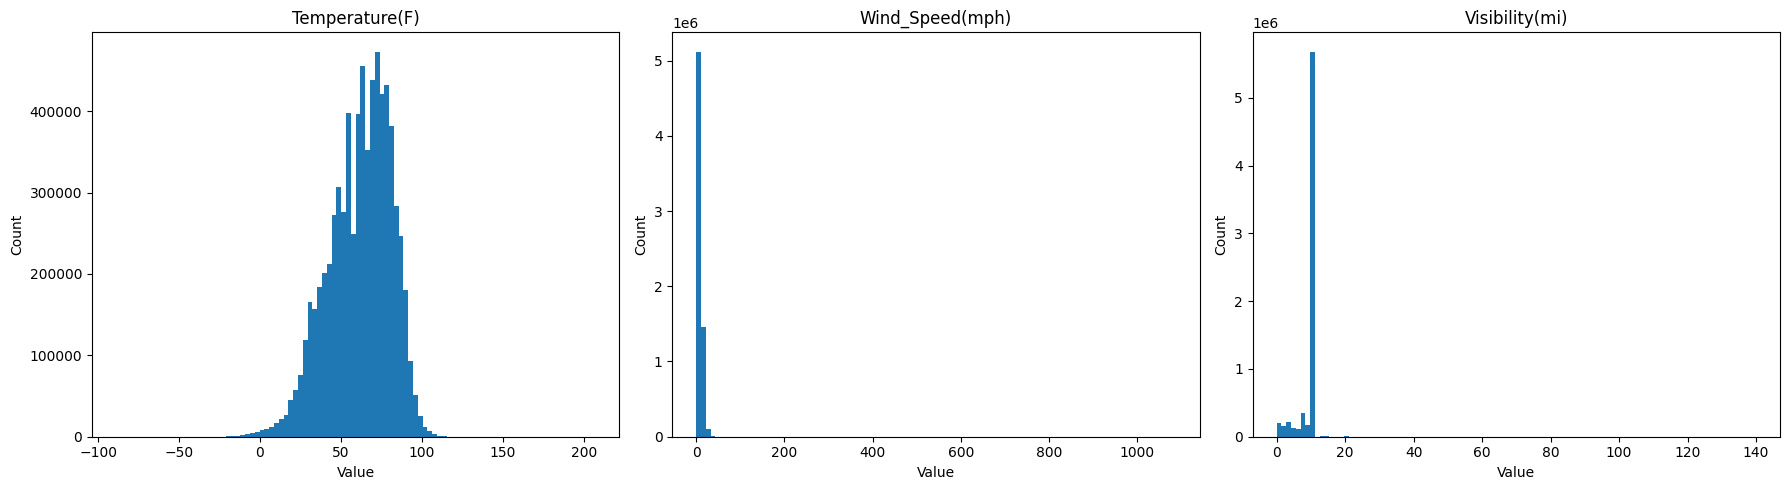

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

cols = ['Temperature(F)', 'Wind_Speed(mph)', 'Visibility(mi)']

for ax, col in zip(axes, cols):
    df[col].dropna().plot(kind='hist', bins=100, ax=ax)
    ax.set_title(col)
    ax.set_xlabel('Value')
    ax.set_ylabel('Count')

plt.tight_layout()
plt.show()

Earlier we already found outliers in temperature and wind speed. Looking at the histograms above, these outliers appear as nearly invisible bars far from the main bulk of data. Visibility also shows extreme values that are barely visible, suggesting they too may be outliers.

However, applying a single global threshold for each variable is not precise because a value that appears extreme overall may be perfectly normal within a specific weather context, and vice versa. But since weather conditions and their associated numeric readings are highly correlated - for example, snow should correspond to temperatures at or below freezing, we asses if they make sense together.

In [ ]:
print(df['Weather_Condition'].value_counts().to_string())

Weather_Condition
Fair                                   2333696
Mostly Cloudy                           953931
Clear                                   804844
Cloudy                                  750152
Partly Cloudy                           657669
Overcast                                381046
Light Rain                              332855
Scattered Clouds                        203860
Light Snow                              119105
Fog                                      91826
Rain                                     79687
Haze                                     71586
Fair / Windy                             32230
Heavy Rain                               30497
Light Drizzle                            21571
Thunder in the Vicinity                  15839
T-Storm                                  15560
Cloudy / Windy                           15452
Mostly Cloudy / Windy                    14800
Snow                                     14248
Thunder                                  1

As shown, there are 143 individual conditions. Since analyzing them separately is impractical, we group them into broader categories such as snow, rain, fog, and clear, assuming conditions within the same group share similar expected value ranges. This way, each row values can be evaluated against what its weather condition would physically imply - keeping in mind that either the sensor reading or the weather condition label itself could be the source of the problem.

In [ ]:
# Create a mask to isolate missing weather data
invalid_mask = df['Weather_Condition'].isna()

# Define the conditions (Order matters: Top condition wins!)
conditions = [
    df['Weather_Condition'].str.contains('Tornado|Funnel|Squalls', case=False, na=False),
    df['Weather_Condition'].str.contains('Snow|Sleet|Wintry|Ice|Freezing|Hail', case=False, na=False),
    df['Weather_Condition'].str.contains('Rain|Drizzle|Shower|Thunder|T-Storm', case=False, na=False),
    df['Weather_Condition'].str.contains('Fog|Mist', case=False, na=False),
    df['Weather_Condition'].str.contains('Haze|Smoke|Dust|Sand|Ash', case=False, na=False),
    df['Weather_Condition'].str.contains('Cloud|Overcast', case=False, na=False),
    df['Weather_Condition'].str.contains('Windy|Blowing', case=False, na=False)
]

# Define the exact matching outputs
choices = [
    'severe_storm',  # Protects extreme physics
    'ice',           # Protects sub-freezing baselines
    'rain',          # Groups all liquid precipitation (including thunder storms)
    'fog',           # Protects high-humidity baselines
    'obscured',      # Dry obscurants
    'cloudy',        # Standard cloud cover
    'windy'          # Standard dry wind
]

# Apply the vectorized logic (Default everything else to 'clear')
df['Weather_Class'] = np.select(conditions, choices, default='clear')

# Protect missing data (Overwrite the 'clear' default with NaN for missing rows)
df.loc[invalid_mask, 'Weather_Class'] = np.nan

# Display order used in all plots below
WEATHER_ORDER = ['clear', 'cloudy', 'ice', 'fog', 'obscured', 'rain', 'windy', 'severe_storm']

In [ ]:
def plot_weather_boxplot(col, ylim=None):
    plt.figure(figsize=(16, 6))
    sns.boxplot(
        data=df[df['Weather_Class'].notna()], # Exclude rows with unknown weather class
        x='Weather_Class',
        y=col,
        order=WEATHER_ORDER, # Consistent ordering across all plots
        flierprops=dict(marker='o', markerfacecolor='white', markersize=2, alpha=0.3),  # Style outlier dots
        showfliers=True # Show extreme values
    )
    plt.title(f'{col} Distribution by Weather Class')
    plt.xlabel('Weather Class')
    plt.ylabel(col)
    plt.xticks(rotation=45, ha='right')
    if ylim is not None:
        plt.ylim(ylim) # Optional y-axis limit to zoom in on the bulk of the data
    plt.tight_layout()
    plt.show()

In [ ]:
def print_boxplot_summary(col):
    for cls in WEATHER_ORDER:
        subset = df[df['Weather_Class'] == cls][col].dropna()  # Isolate non-null values for this weather class
        if len(subset) == 0:
            continue

        q1, median, q3 = subset.quantile([0.25, 0.5, 0.75])
        iqr = q3 - q1 # Interquartile range — the spread of the middle 50%

        # Whisker endpoints follow the standard 1.5 * IQR rule used by seaborn's boxplot
        whisker_low = subset[subset >= q1 - 1.5 * iqr].min()
        whisker_high = subset[subset <= q3 + 1.5 * iqr].max()

        # Dots (extreme values) are values that fall outside the whisker range
        dots_low = subset[subset < whisker_low]
        dots_high = subset[subset > whisker_high]

        print(f'  {cls}:')
        print(f'    Box:          Q1={q1:.1f}, Median={median:.1f}, Q3={q3:.1f}')
        print(f'    Whiskers:     low={whisker_low:.1f}, high={whisker_high:.1f}')
        if len(dots_low) > 0:
            print(f'    Dots (low):   min={dots_low.min():.1f}, max={dots_low.max():.1f}, count={len(dots_low)}')
        if len(dots_high) > 0:
            print(f'    Dots (high):  min={dots_high.min():.1f}, max={dots_high.max():.1f}, count={len(dots_high)}')
        if len(dots_low) == 0 and len(dots_high) == 0:
            print(f'    Dots:         none')

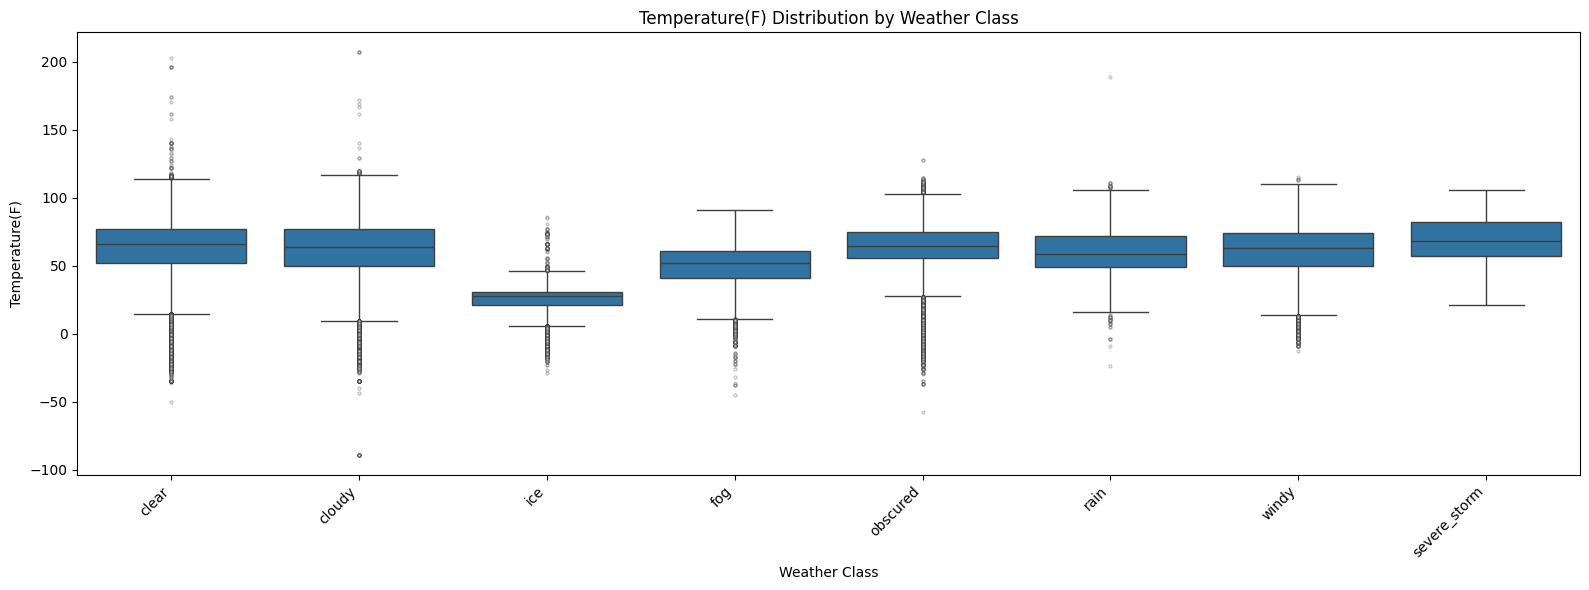

In [ ]:
plot_weather_boxplot('Temperature(F)')

In [ ]:
print_boxplot_summary('Temperature(F)')

  clear:
    Box:          Q1=52.0, Median=66.0, Q3=77.0
    Whiskers:     low=14.5, high=114.1
    Dots (low):   min=-50.0, max=14.4, count=36216
    Dots (high):  min=114.8, max=203.0, count=110
  cloudy:
    Box:          Q1=50.0, Median=64.0, Q3=77.0
    Whiskers:     low=9.5, high=117.0
    Dots (low):   min=-89.0, max=9.3, count=13784
    Dots (high):  min=118.0, max=207.0, count=31
  ice:
    Box:          Q1=21.0, Median=28.0, Q3=31.0
    Whiskers:     low=6.0, high=46.0
    Dots (low):   min=-29.0, max=5.9, count=6901
    Dots (high):  min=46.4, max=86.0, count=114
  fog:
    Box:          Q1=41.0, Median=52.0, Q3=61.0
    Whiskers:     low=11.0, high=91.0
    Dots (low):   min=-45.0, max=10.9, count=428
  obscured:
    Box:          Q1=55.9, Median=64.9, Q3=75.0
    Whiskers:     low=27.5, high=103.0
    Dots (low):   min=-58.0, max=27.1, count=4831
    Dots (high):  min=104.0, max=128.0, count=262
  rain:
    Box:          Q1=49.0, Median=59.0, Q3=72.0
    Whiskers:     low=

Temperature is largely independent of weather type - a rainy day in Miami and a clear day in NYC can both be 55°F. This is why most weather classes share a similar temperature distribution, with ice being the natural exception as frozen precipitation requires near-freezing temperatures. Obscured also stands out with a slightly higher temperature distribution, which makes sense - smoke, haze, and dust storms are strongly associated with hot dry weather and wildfires. Across all classes there are a small number of extreme values sitting far beyond the whiskers - reaching 200°F+ and below -50°F, which are physically impossible and are clearly errors.

For all classes we apply IQR 1.5x on both tails to remove extreme errors while preserving legitemate seasonal temperature differences. For ice we only apply it on the lower tail - the upper tail is left untouched to preserve valid hail records that occur at warm surface temperatures.

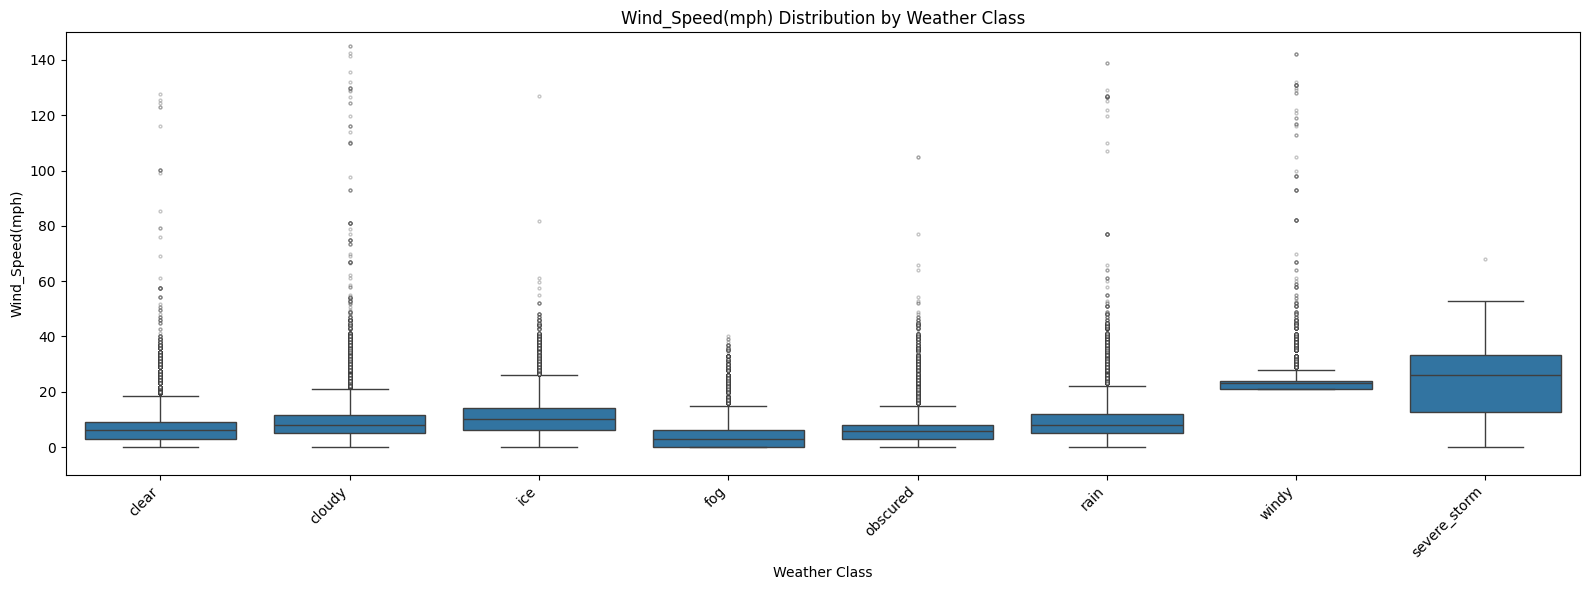

In [ ]:
plot_weather_boxplot('Wind_Speed(mph)', ylim=(-10, 150))

In [ ]:
print_boxplot_summary('Wind_Speed(mph)')

  clear:
    Box:          Q1=3.0, Median=6.0, Q3=9.2
    Whiskers:     low=0.0, high=18.4
    Dots (high):  min=19.6, max=822.8, count=25446
  cloudy:
    Box:          Q1=5.0, Median=8.0, Q3=11.5
    Whiskers:     low=0.0, high=21.0
    Dots (high):  min=21.9, max=1087.0, count=44153
  ice:
    Box:          Q1=6.0, Median=10.0, Q3=14.0
    Whiskers:     low=0.0, high=26.0
    Dots (high):  min=26.5, max=127.0, count=2946
  fog:
    Box:          Q1=0.0, Median=3.0, Q3=6.0
    Whiskers:     low=0.0, high=15.0
    Dots (high):  min=16.0, max=40.0, count=1520
  obscured:
    Box:          Q1=3.0, Median=5.8, Q3=8.1
    Whiskers:     low=0.0, high=15.0
    Dots (high):  min=16.0, max=105.0, count=4632
  rain:
    Box:          Q1=5.0, Median=8.0, Q3=12.0
    Whiskers:     low=0.0, high=22.0
    Dots (high):  min=23.0, max=241.7, count=11512
  windy:
    Box:          Q1=21.0, Median=23.0, Q3=24.0
    Whiskers:     low=21.0, high=28.0
    Dots (high):  min=29.0, max=984.0, count=2877
  s

Fog requires calm air, windy and severe storm are defined by strong winds, and most other classes sit somewhere in between. Fog stands out with a near-zero median wind, consistent with the fact that wind physically disperses fog.

Across nearly all classes there are extreme values far beyond the whiskers that are physically impossible - reaching 823, 1087, and 984 mph - these are pure errors. For fog, values above 15 mph contradict the classification. For severe storm, there are near-zero wind readings which are impossible for a severe storm - and since this class has little number of records, the IQR boundaries are computed on a very small sample and are statistically unreliable.

For most classes we apply IQR 1.5x. For fog we remove values above 15 mph, as wind that strong contradicts the fog classification. For severe storm, applying a meaningful lower threshold - 45 mph, the point at which driving becomes genuinely hazardous, would remove the vast majority of records, leaving the class statistically meaningless. These records are therefore reclassified as windy, which better reflects their actual wind readings and merges them into a larger, more robust group.

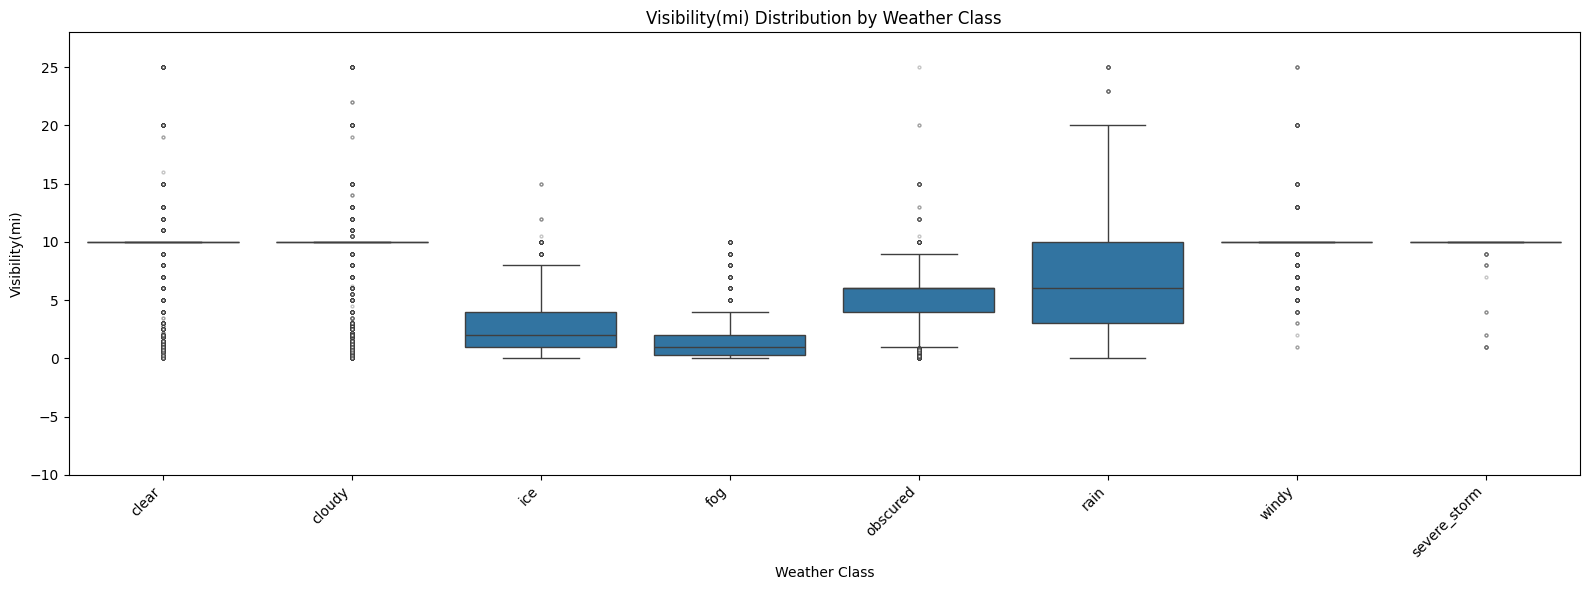

In [ ]:
plot_weather_boxplot('Visibility(mi)', ylim=(-10, 28))

In [ ]:
print_boxplot_summary('Visibility(mi)')

  clear:
    Box:          Q1=10.0, Median=10.0, Q3=10.0
    Whiskers:     low=10.0, high=10.0
    Dots (low):   min=0.0, max=9.0, count=219376
    Dots (high):  min=11.0, max=140.0, count=11463
  cloudy:
    Box:          Q1=10.0, Median=10.0, Q3=10.0
    Whiskers:     low=10.0, high=10.0
    Dots (low):   min=0.0, max=9.0, count=413834
    Dots (high):  min=10.5, max=111.0, count=17259
  ice:
    Box:          Q1=1.0, Median=2.0, Q3=4.0
    Whiskers:     low=0.0, high=8.0
    Dots (high):  min=9.0, max=42.0, count=13843
  fog:
    Box:          Q1=0.2, Median=1.0, Q3=2.0
    Whiskers:     low=0.0, high=4.0
    Dots (high):  min=5.0, max=80.0, count=7122
  obscured:
    Box:          Q1=4.0, Median=6.0, Q3=6.0
    Whiskers:     low=1.0, high=9.0
    Dots (low):   min=0.0, max=0.9, count=1193
    Dots (high):  min=10.0, max=76.0, count=5235
  rain:
    Box:          Q1=3.0, Median=6.0, Q3=10.0
    Whiskers:     low=0.0, high=20.0
    Dots (high):  min=23.0, max=105.0, count=81
  windy:

The clear class is particularly telling - almost all its values sit at exactly 10 mi, confirming that 10 mi is the hard reporting cap of the sensors, not an arbitrary threshold. Any value above 10 mi across any class is therefore considered an error.

Beyond that, the plot shows a clean split between two groups. Classes where something physically blocks visibility - ice, fog, obscured, and rain - show wide distributions with meaningful variation below 10 mi. Cloudy and windy also collapse at 10 mi, which makes physical sense - clouds and wind alone do not block horizontal visibility.

For all classes we remove values above 10 mi. For clear, cloudy, and windy we additionally remove values below 5 mi since anything below 5 mi is almost certainly an error in the sensor value or the row is misclassified. For ice, fog, and obscured we apply IQR 1.5× on the upper tail only - their distributions sit well below 10 mi, so suspiciously high readings are inconsistent with those classifications. For rain, values below 10 mi are left untouched - reduced visibility during precipitation is physically explainable and not necessarily an error.

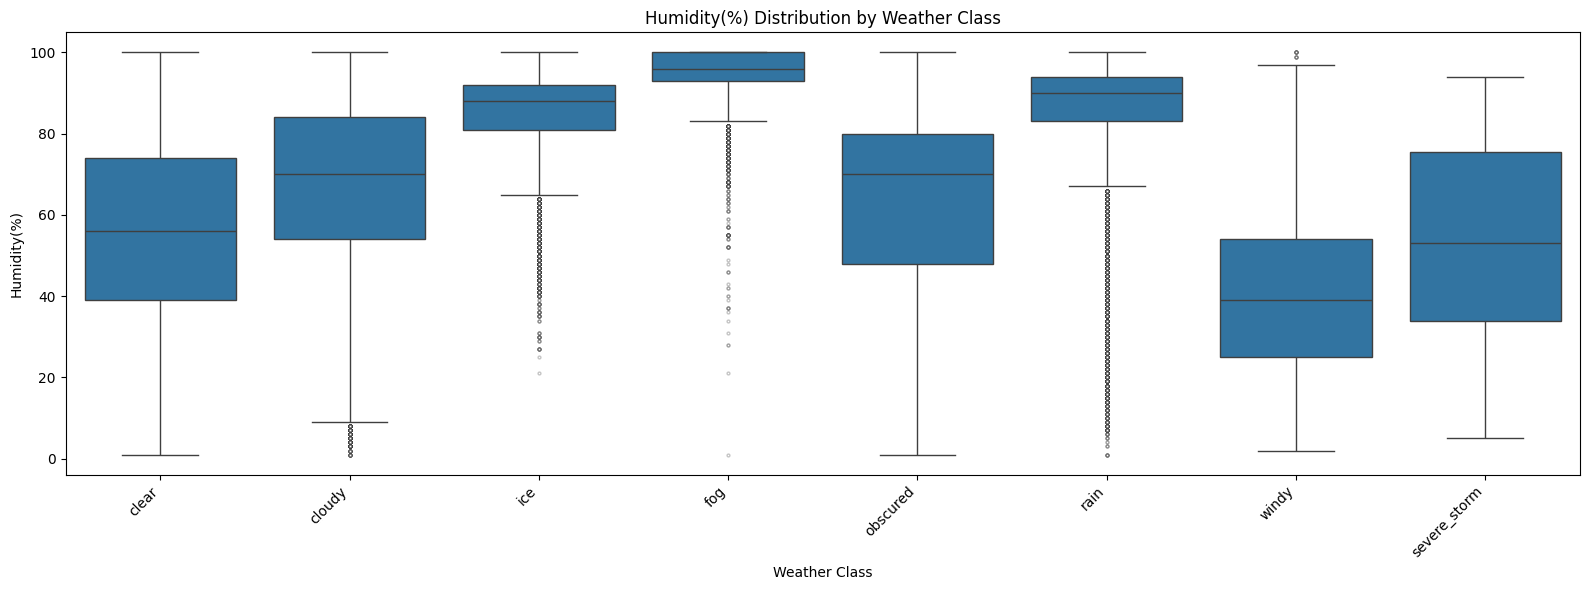

In [ ]:
plot_weather_boxplot('Humidity(%)')

In [ ]:
print_boxplot_summary('Humidity(%)')

  clear:
    Box:          Q1=39.0, Median=56.0, Q3=74.0
    Whiskers:     low=1.0, high=100.0
    Dots:         none
  cloudy:
    Box:          Q1=54.0, Median=70.0, Q3=84.0
    Whiskers:     low=9.0, high=100.0
    Dots (low):   min=1.0, max=8.0, count=4477
  ice:
    Box:          Q1=81.0, Median=88.0, Q3=92.0
    Whiskers:     low=65.0, high=100.0
    Dots (low):   min=21.0, max=64.0, count=3816
  fog:
    Box:          Q1=93.0, Median=96.0, Q3=100.0
    Whiskers:     low=83.0, high=100.0
    Dots (low):   min=1.0, max=82.0, count=968
  obscured:
    Box:          Q1=48.0, Median=70.0, Q3=80.0
    Whiskers:     low=1.0, high=100.0
    Dots:         none
  rain:
    Box:          Q1=83.0, Median=90.0, Q3=94.0
    Whiskers:     low=67.0, high=100.0
    Dots (low):   min=1.0, max=66.0, count=33740
  windy:
    Box:          Q1=25.0, Median=39.0, Q3=54.0
    Whiskers:     low=2.0, high=97.0
    Dots (high):  min=99.0, max=100.0, count=13
  severe_storm:
    Box:          Q1=34.0, Medi

Fog sits near 100% as expected since fog is water droplets suspended in air. Rain and ice sit high, consistent with the moisture required for precipitation. Windy and clear sit lower, as both occur frequently in dry environments. Obscured spans a wide range - smoke and dust are dry, but haze can form at humidity levels up to 90% as aerosol particles absorb moisture.

The problematic values are near-zero humidity readings in cloudy, ice, fog, and rain - all of which require significant moisture and these are clearly errors.

For cloudy, ice, fog, and rain we apply IQR 1.5x on the lower tail only. For all other classes no action is needed.

---

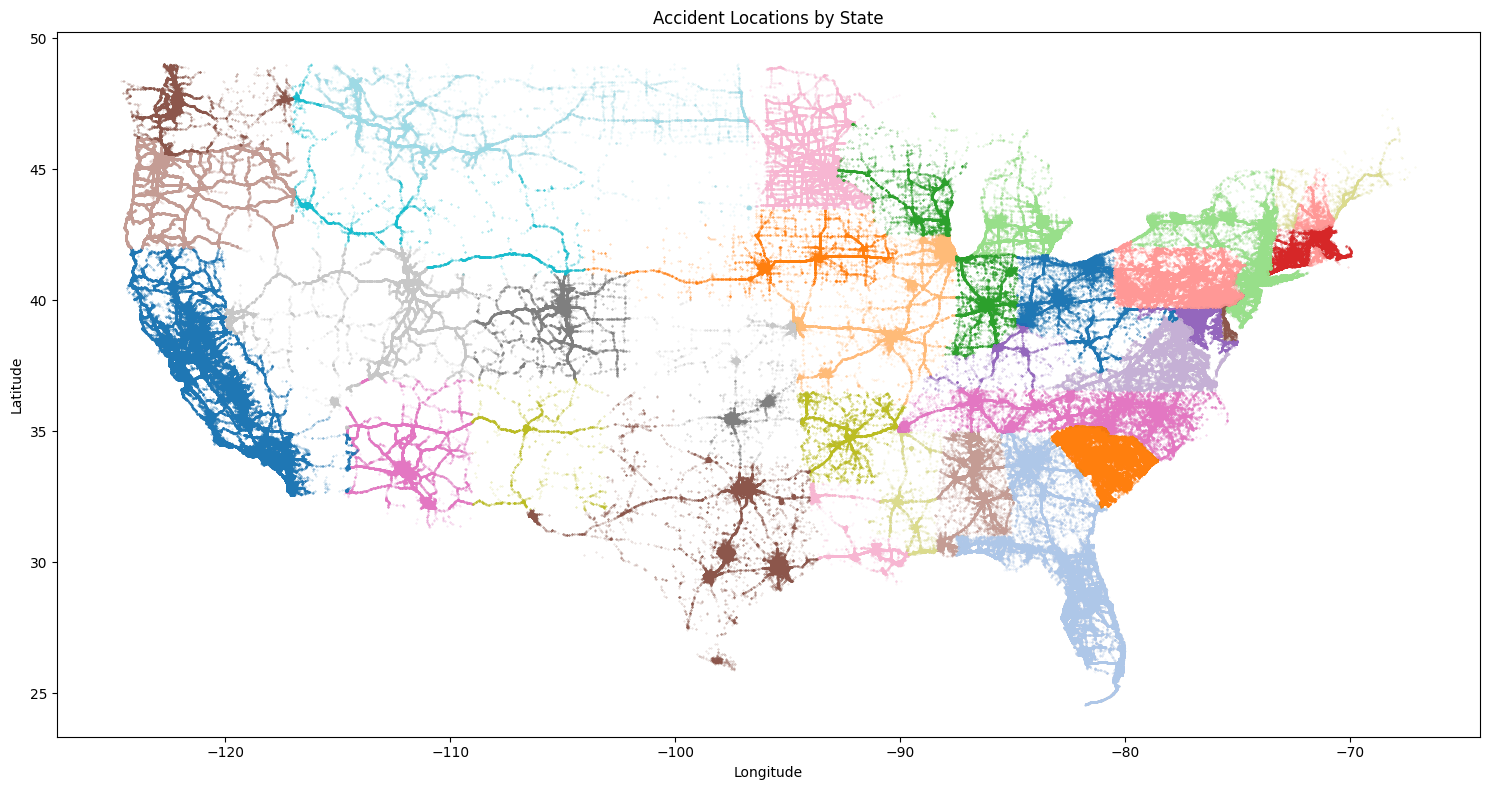

In [ ]:
plt.figure(figsize=(15, 8))

states = df['State'].unique()
colors = plt.cm.tab20(np.linspace(0, 1, len(states)))
state_color_map = dict(zip(states, colors))

for state, group in df.groupby('State'):
    plt.scatter(
        group['Start_Lng'],
        group['Start_Lat'],
        c=[state_color_map[state]],
        label=state,
        s=0.1,      # very small dots since we have millions of points
        alpha=0.3
    )

plt.title('Accident Locations by State')
plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.tight_layout()
plt.show()

The plotted coordinates not only appear well-separated by their tagged states, but together they almost perfectly reconstruct the shape of the US map, suggesting the coordinate data is reliable.

---

## Data Preparation

#### Variables Renaming

In [ ]:
df.rename(columns={
    'Severity':        'Traffic_Impact',
    'Start_Time':      'Datetime',
    'Start_Lat':       'Latitude',
    'Start_Lng':       'Longitude',
    'Street':          'Road',
    'Civil_Twilight':  'Is_Day'
}, inplace=True)

#### Filling Is_Day Missing Values

In [ ]:
def get_is_day(row):
    # Round to 1 decimal place - sufficient for sunrise/sunset calculation
    lat = round(row['Latitude'], 1)
    lng = round(row['Longitude'], 1)

    # Get local timezone from coordinates
    tz_name = tf.timezone_at(lat=lat, lng=lng)
    tz = pytz.timezone(tz_name)

    location = LocationInfo(latitude=lat, longitude=lng)
    try:
        s = sun(location.observer, date=row['Datetime'].date(), tzinfo=tz) # Get sunrise/sunset times in local timezone
        dawn = s['dawn'].replace(tzinfo=None) # Strip tzinfo so it can be compared against the naive Datetime column
        dusk = s['dusk'].replace(tzinfo=None)
        return 'Day' if dawn <= row['Datetime'] <= dusk else 'Night'
    except ValueError:
        return np.nan # Can't determine - leave as missing

In [ ]:
# Only process rows where Is_Day is missing
missing_mask = df['Is_Day'].isna()
missing_df = df[missing_mask]

print(f"Filling {missing_mask.sum():,} missing Is_Day values...")

Filling 20,507 missing Is_Day values...


In [ ]:
df.loc[missing_mask, 'Is_Day'] = missing_df.apply(get_is_day, axis=1)
print(f"Done. Remaining NaNs in Is_Day: {df['Is_Day'].isna().sum()}")

Done. Remaining NaNs in Is_Day: 0


In [ ]:
# Sanity check: manually verify a sample of filled rows against expected sunrise/sunset
sample = df[missing_mask].sample(10, random_state=42)[['Latitude', 'Longitude', 'Datetime', 'Is_Day']]
print(sample.to_string())

          Latitude   Longitude            Datetime Is_Day
5051731  27.715616  -82.666997 2022-01-18 14:53:01    Day
3762027  40.923387  -73.823960 2022-05-17 16:19:13    Day
3989104  27.790512  -82.679394 2022-02-04 20:16:30  Night
5526385  27.802330  -82.662431 2021-07-19 07:15:00    Day
3689187  27.767323  -82.705298 2022-05-12 12:32:45    Day
4107722  33.666980 -101.665756 2022-08-16 13:41:00    Day
4116445  40.193101  -85.282998 2023-01-06 08:18:10    Day
4135444  36.057709  -80.259263 2022-06-18 14:42:00    Day
4264372  40.264434 -106.945260 2022-09-25 20:00:35  Night
6251692  34.739574 -114.244305 2021-10-26 01:48:30  Night


#### Handling Outliers

| Weather Class | Temperature | Wind Speed | Visibility | Humidity |
|---|---|---|---|---|
| **clear** | IQR 1.5× both tails | IQR 1.5× both tails | Null > 10 mi. Remove < 5 mi | No action |
| **cloudy** | IQR 1.5× both tails | IQR 1.5× both tails | Null > 10 mi. Remove < 5 mi | IQR 1.5× lower tail only |
| **ice** | IQR 1.5× lower tail only | IQR 1.5× both tails | IQR 1.5× upper tail only | IQR 1.5× lower tail only |
| **fog** | IQR 1.5× both tails | Hard threshold: remove > 15 mph | IQR 1.5× upper tail only | IQR 1.5× lower tail only |
| **obscured** | IQR 1.5× both tails | IQR 1.5× both tails | IQR 1.5× upper tail only | No action |
| **rain** | IQR 1.5× both tails | IQR 1.5× both tails | Null > 10 mi. Leave values below untouched | IQR 1.5× lower tail only |
| **windy** | IQR 1.5× both tails | IQR 1.5× both tails | Null > 10 mi. Remove < 5 mi | No action |

*\* Records originally tagged as `severe_storm` are reclassified as `windy` prior to outlier removal - see wind speed assessment under Data Validity section.*

In [ ]:
df.loc[df['Weather_Class'] == 'severe_storm', 'Weather_Class'] = 'windy'
WEATHER_ORDER = ['clear', 'cloudy', 'ice', 'fog', 'obscured', 'rain', 'windy']

In [ ]:
# Rules table: defines the outlier removal strategy per column per weather class
# Mirrors the cleaning table defined above
RULES = {
    'Temperature(F)': {
        'clear':    'iqr_both',
        'cloudy':   'iqr_both',
        'ice':      'iqr_lower',  # Upper tail left untouched to preserve valid hail records at warm temperatures
        'fog':      'iqr_both',
        'obscured': 'iqr_both',
        'rain':     'iqr_both',
        'windy':    'iqr_both'
    },
    'Wind_Speed(mph)': {
        'clear':    'iqr_both',
        'cloudy':   'iqr_both',
        'ice':      'iqr_both',
        'fog':      ('hard_upper', 15),  # Wind above 15 mph physically contradicts fog classification
        'obscured': 'iqr_both',
        'rain':     'iqr_both',
        'windy':    'iqr_both'
    },
        'Visibility(mi)': {
        'clear':    ('hard_upper', 10, 'hard_lower', 5), # 10 mi is sensor cap, below 5 mi contradicts clear conditions
        'cloudy':   ('hard_upper', 10, 'hard_lower', 5),
        'ice':      'iqr_upper',
        'fog':      'iqr_upper',
        'obscured': 'iqr_upper',
        'rain':     ('hard_upper', 10),  # Reduced visibility during rain is physically explainable
        'windy':    ('hard_upper', 10, 'hard_lower', 5)
    },
    'Humidity(%)': {
        'clear':    'no_action',
        'cloudy':   'iqr_lower',
        'ice':      'iqr_lower',
        'fog':      'iqr_lower',
        'obscured': 'no_action',  # Wide humidity range expected - smoke/dust are dry, haze can be humid
        'rain':     'iqr_lower',
        'windy':    'no_action'
        # Lower tail only - near-zero humidity is impossible for moisture-dependent classes
    }
}

In [ ]:
IQR_MULTIPLIER = 1.5

In [ ]:
# Step 1: Compute all IQR bounds BEFORE any nulling
# This ensures that early removals don't affect the bounds used for later columns
bounds = {}
for col, class_rules in RULES.items():
    bounds[col] = {}
    for cls, rule in class_rules.items():
        if 'iqr' not in str(rule):
            continue
        subset = df[df['Weather_Class'] == cls][col].dropna()
        q1, q3 = subset.quantile([0.25, 0.75])
        iqr = q3 - q1
        bounds[col][cls] = {
            'lower': q1 - IQR_MULTIPLIER * iqr,
            'upper': q3 + IQR_MULTIPLIER * iqr
        }

In [ ]:
# Step 2: Apply all rules, nulling out values that fall outside the defined thresholds
for col, class_rules in RULES.items():
    for cls, rule in class_rules.items():
        mask = df['Weather_Class'] == cls  # Isolate rows for this weather class

        if rule == 'no_action':
            continue

        elif rule == 'iqr_both':
            lower = bounds[col][cls]['lower']
            upper = bounds[col][cls]['upper']
            df.loc[mask & ((df[col] < lower) | (df[col] > upper)), col] = np.nan

        elif rule == 'iqr_lower':
            lower = bounds[col][cls]['lower']
            df.loc[mask & (df[col] < lower), col] = np.nan

        elif rule == 'iqr_upper':
            upper = bounds[col][cls]['upper']
            df.loc[mask & (df[col] > upper), col] = np.nan

        elif rule[0] == 'hard_upper' and len(rule) == 2:
            df.loc[mask & (df[col] > rule[1]), col] = np.nan

        elif rule[0] == 'hard_upper' and len(rule) == 4:  # Clear visibility: hard bounds on both sides
            df.loc[mask & ((df[col] > rule[1]) | (df[col] < rule[3])), col] = np.nan

In [ ]:
# Step 3: Flag rows with fewer than 3 valid numeric values as unknown weather
# These rows have lost too much sensor data to be reliably classified
NUMERIC_COLS = ['Temperature(F)', 'Wind_Speed(mph)', 'Visibility(mi)', 'Humidity(%)']
null_count = df[NUMERIC_COLS].isnull().sum(axis=1)
df.loc[null_count >= 2, 'Weather_Class'] = np.nan

print(f"Total unknown weather rows: {df['Weather_Class'].isna().sum():,}")

Total unknown weather rows: 232,525


In [ ]:
def plot_weather_violin(col, ylim=None):
    plt.figure(figsize=(16, 6))
    sns.violinplot(
        data=df[df['Weather_Class'].notna()],  # Exclude rows with unknown weather class
        x='Weather_Class',
        y=col,
        order=WEATHER_ORDER,  # Consistent ordering across all plots
        inner='box',          # Show median and IQR inside each violin
        density_norm='width'  # All violins same width for easier comparison
    )
    plt.title(f'{col} Distribution by Weather Class (Post-Cleaning)')
    plt.xlabel('Weather Class')
    plt.ylabel(col)
    plt.xticks(rotation=45, ha='right')
    if ylim is not None:
        plt.ylim(ylim)
    plt.tight_layout()
    plt.show()

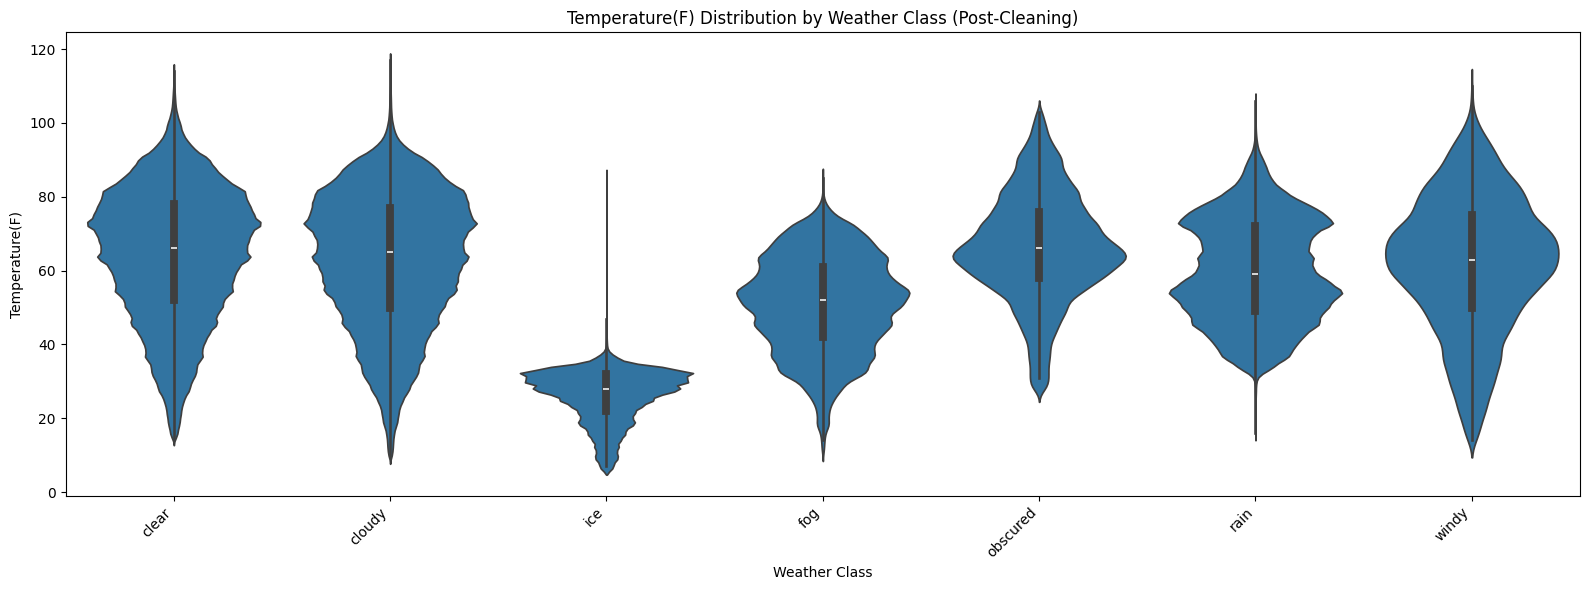

In [ ]:
plot_weather_violin('Temperature(F)')

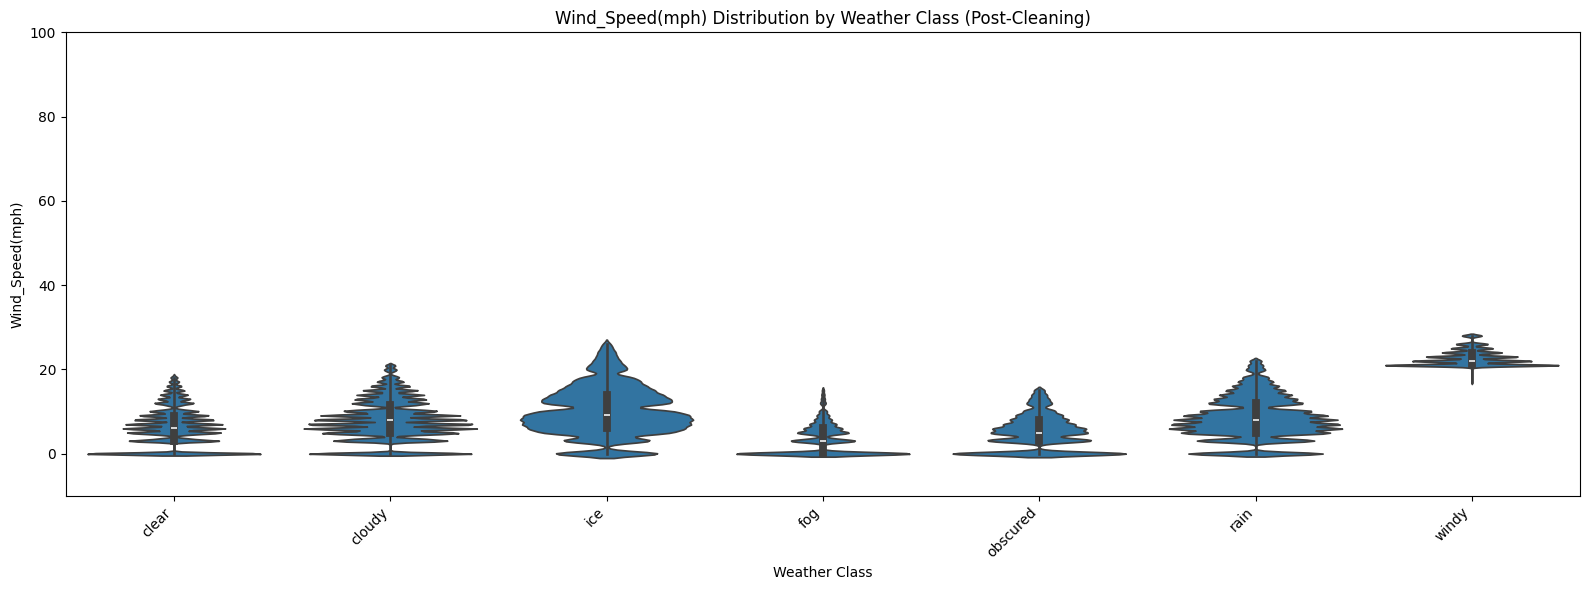

In [ ]:
plot_weather_violin('Wind_Speed(mph)', ylim=(-10, 100))

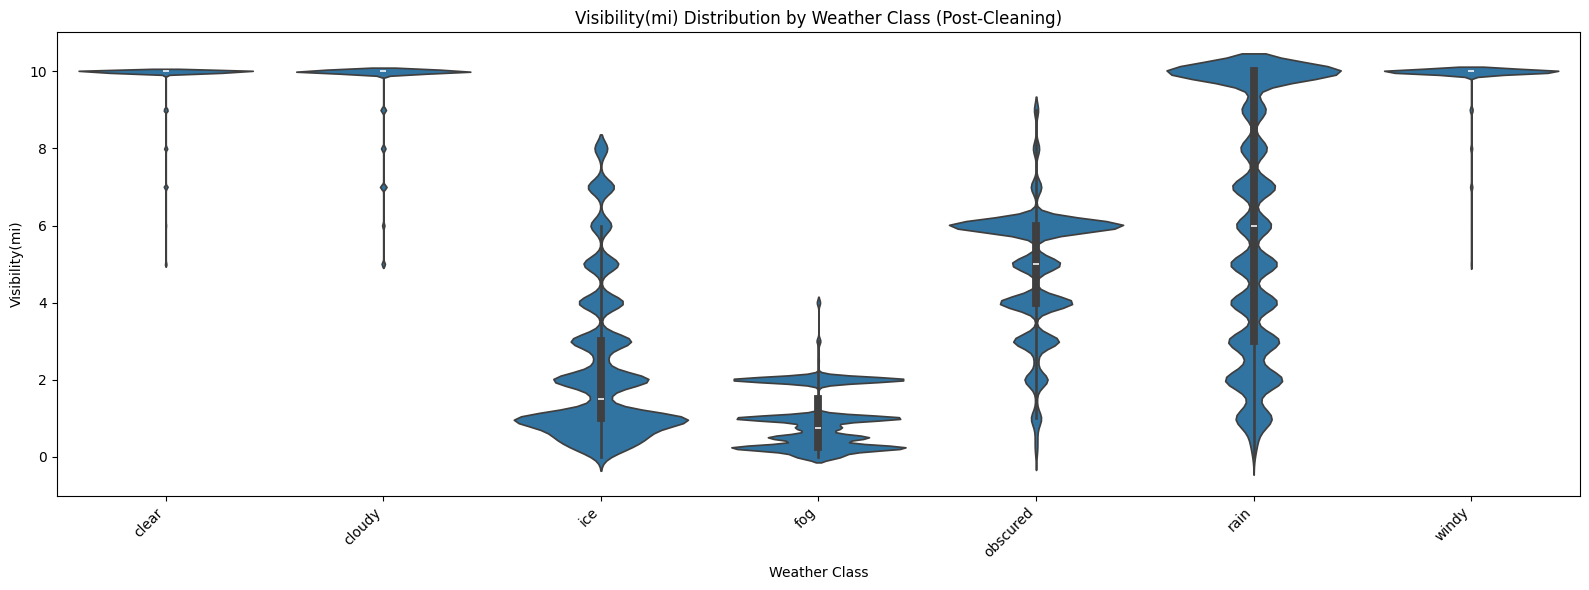

In [ ]:
plot_weather_violin('Visibility(mi)')

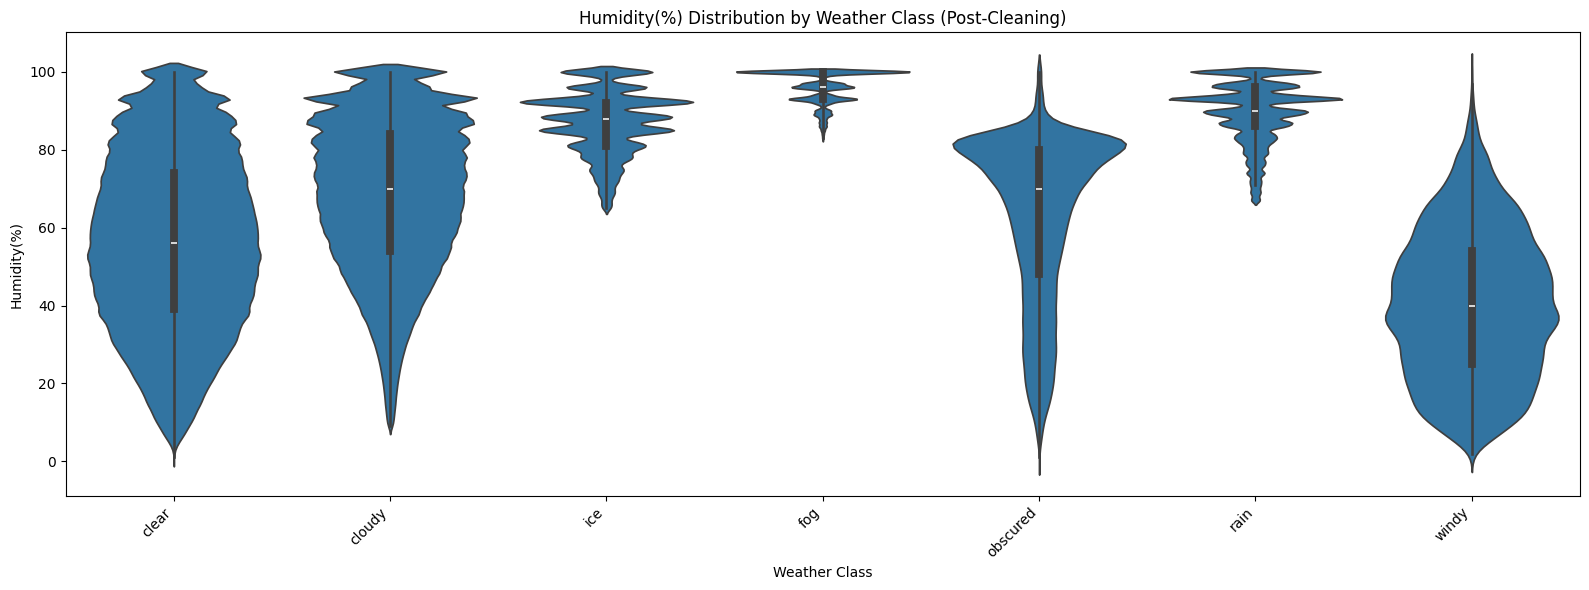

In [ ]:
plot_weather_violin('Humidity(%)')

### Feature Removal

Now that **`Weather_Class`** merges all 143 individual weather conditions into groups, **`Weather_Condition`** is redundant and will be dropped. Similarly, the numeric weather columns - **`Temperature(F)`**, **`Wind_Speed(mph)`**, **`Visibility(mi)`**, and **`Humidity(%)`**, served their purpose in validating and cleaning the weather classifications and are no longer needed for the analysis itself.

In [ ]:
df.drop(columns=['Weather_Condition', 'Temperature(F)', 'Wind_Speed(mph)', 'Visibility(mi)', 'Humidity(%)'], inplace=True)

### Dtype Optimization

In [ ]:
# Traffic_Impact: ordered categorical (1 = least disruptive, 4 = most disruptive)
df['Traffic_Impact'] = pd.Categorical(
    df['Traffic_Impact'],
    categories=[1, 2, 3, 4],
    ordered=True
)

# Is_Day: map Day/Night to True/False
df['Is_Day'] = df['Is_Day'].map({'Day': True, 'Night': False}).astype(pd.BooleanDtype())

# Downcast coordinates from float64 to float32
df['Latitude']  = df['Latitude'].astype('float32')
df['Longitude'] = df['Longitude'].astype('float32')

# Low cardinality string columns to category
for col in ['State', 'City', 'Weather_Class']:
    df[col] = df[col].astype('category')

### Feature Creation

In [ ]:
# Season mapping based on month (Northern Hemisphere standard)
# Dec-Feb: Winter, Mar-May: Spring, Jun-Aug: Summer, Sep-Nov: Fall
def get_season(month):
    if month in [12, 1, 2]:
        return 'Winter'
    elif month in [3, 4, 5]:
        return 'Spring'
    elif month in [6, 7, 8]:
        return 'Summer'
    else:
        return 'Fall'

In [ ]:
df['Season'] = df['Datetime'].dt.month.map(get_season)

In [ ]:
df['Season'] = df['Season'].astype('category')

In [ ]:
# Compile patterns once for performance (called on 7M+ rows)
_INTERSTATE = re.compile(r'\bI-\d+\b|\bInterstate\b', re.IGNORECASE)
_HIGHWAY    = re.compile(r'\bUS-\d+\b|\bUS Highway\b|\bSR-\d+\b|\bState R(oad|oute)\b|\bHighway\b|\bCR-\d+\b|\bCounty Road\b', re.IGNORECASE)

In [ ]:
def get_road_type(road):
    if pd.isna(road):
        return np.nan
    road = str(road).strip()
    # Priority order: Interstate > Highway > Local Road
    if _INTERSTATE.search(road):
        return 'Interstate' # Interstate: Major divided highways connecting states (e.g. I-95, I-80) - highest speed limits, no traffic lights
    elif _HIGHWAY.search(road):
        return 'Highway' # Highway: US and State maintained highways (e.g. US-301, SR-42) - high speed limits, occasional traffic lights
    else:
        return 'Local Road' # Local Road:  All other named roads, city streets, county and access roads

In [ ]:
df['Road_Type'] = df['Road'].map(get_road_type)

In [ ]:
df['Road_Type'] = df['Road_Type'].astype('category')

### Final Dataframe Description

In [ ]:
df.describe(include='all').T

,count,unique,top,freq,mean,min,25%,50%,75%,max,std
Traffic_Impact,7240402.0,4.0,2.0,5687629.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Datetime,7240402,NaN,NaN,NaN,2020-05-04 08:02:51.827541248,2016-01-14 20:18:33,2018-10-14 15:49:23.249999872,2020-09-29 12:43:30,2021-12-28 17:43:00,2023-03-31 23:30:00,NaN
Latitude,7240402.0,NaN,NaN,NaN,36.231339,24.5548,33.434952,35.817329,40.07177,49.002201,5.005975
Longitude,7240402.0,NaN,NaN,NaN,-94.785515,-124.623833,-117.218201,-87.9132,-80.400711,-67.113167,17.295729
Road,7230798,336306,I-95 N,74594,NaN,NaN,NaN,NaN,NaN,NaN,NaN
City,7240165,13678,Houston,163346,NaN,NaN,NaN,NaN,NaN,NaN,NaN
State,7240402,49,CA,1630336,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Bump,7240402,2,False,7237196,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Crossing,7240402,2,False,6426481,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Give_Way,7240402,2,False,7205684,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 7240402 entries, 0 to 7728393
Data columns (total 20 columns):
 #   Column          Dtype         
---  ------          -----         
 0   Traffic_Impact  category      
 1   Datetime        datetime64[ns]
 2   Latitude        float32       
 3   Longitude       float32       
 4   Road            object        
 5   City            category      
 6   State           category      
 7   Bump            bool          
 8   Crossing        bool          
 9   Give_Way        bool          
 10  Junction        bool          
 11  Railway         bool          
 12  Roundabout      bool          
 13  Station         bool          
 14  Stop            bool          
 15  Traffic_Signal  bool          
 16  Is_Day          boolean       
 17  Weather_Class   category      
 18  Season          category      
 19  Road_Type       category      
dtypes: bool(9), boolean(1), category(6), datetime64[ns](1), float32(2), object(1)
memory usage: 345

## Analysis

### **How Serious is The Road Accident Problem in the US, and which Regions are Most Affected?**

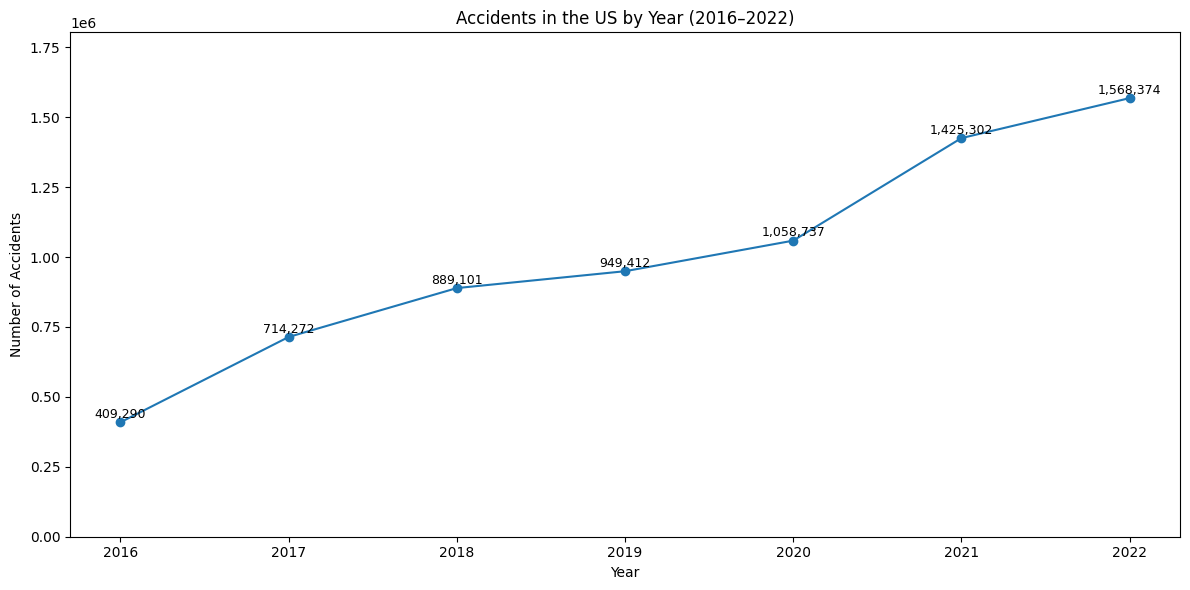

In [ ]:
# ── Accidents by Year (2016-2022, excluding incomplete 2023) ─────────────────
yearly = df[df['Datetime'].dt.year != 2023].groupby(df['Datetime'].dt.year).size()

fig, ax = plt.subplots(figsize=(12, 6))
ax.plot(yearly.index, yearly.values, marker='o')

for x, y in zip(yearly.index, yearly.values):
    ax.text(x, y + yearly.values.max() * 0.01, f'{y:,}', ha='center', fontsize=9)

ax.set_title('Accidents in the US by Year (2016–2022)')
ax.set_xlabel('Year')
ax.set_ylabel('Number of Accidents')
ax.set_xticks(yearly.index)
ax.set_ylim(0, yearly.values.max() * 1.15)
plt.tight_layout()
plt.show()

Traffic accidents are a growing problem in the US - the dataset shows a clear upward trend in accident counts year over year from 2016 to 2022, suggesting that despite advances in vehicle safety technology, roads are becoming more dangerous.

Notably, official reports indicate that traffic accidents actually decreased nationwide during 2020 due to COVID-19 lockdowns reducing traffic volume, yet our dataset shows no such drop so we will examine 2020 more closely.

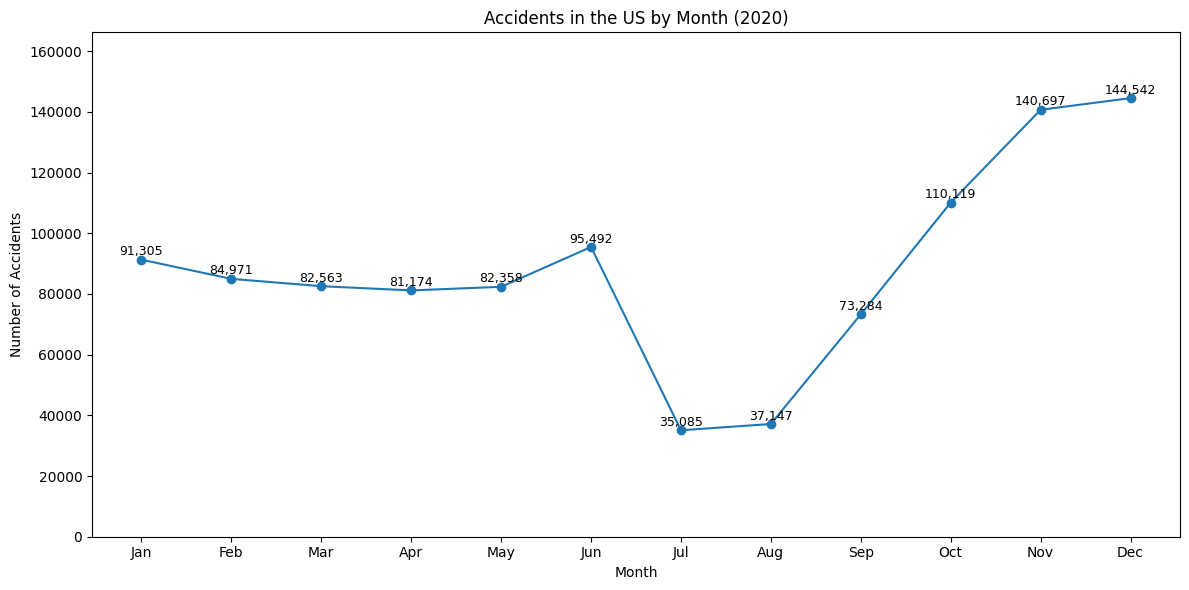

In [ ]:
# ── Accidents in 2020 by Month ───────────────────────────────────────────────
monthly_2020 = (
    df[df['Datetime'].dt.year == 2020]
    .groupby(df['Datetime'].dt.month)
    .size()
)

month_names = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun',
               'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']

fig, ax = plt.subplots(figsize=(12, 6))
ax.plot(month_names, monthly_2020.values, marker='o')

for x, y in zip(month_names, monthly_2020.values):
    ax.text(x, y + monthly_2020.values.max() * 0.01, f'{y:,}', ha='center', fontsize=9)

ax.set_title('Accidents in the US by Month (2020)')
ax.set_xlabel('Month')
ax.set_ylabel('Number of Accidents')
ax.set_ylim(0, monthly_2020.values.max() * 1.15)
plt.tight_layout()
plt.show()

The monthly distribution for 2020 reveals an unexpected pattern. Rather than a clear drop in March–April corresponding to COVID-19 lockdowns, the data shows a dramatic decline in July–August followed by a sharp recovery through the end of the year. This does not align with any known real-world event and is almost certainly an artifact of the data collection process, likely a temporary outage or reduced coverage from one or more of the traffic-reporting APIs that fed this dataset.

This serves as a good reminder that this dataset does not perfectly reflect reality. However, it still provides a strong overall view.

In [ ]:
STATE_NAMES = {
    'AL': 'Alabama', 'AK': 'Alaska', 'AZ': 'Arizona', 'AR': 'Arkansas',
    'CA': 'California', 'CO': 'Colorado', 'CT': 'Connecticut', 'DE': 'Delaware',
    'FL': 'Florida', 'GA': 'Georgia', 'HI': 'Hawaii', 'ID': 'Idaho',
    'IL': 'Illinois', 'IN': 'Indiana', 'IA': 'Iowa', 'KS': 'Kansas',
    'KY': 'Kentucky', 'LA': 'Louisiana', 'ME': 'Maine', 'MD': 'Maryland',
    'MA': 'Massachusetts', 'MI': 'Michigan', 'MN': 'Minnesota', 'MS': 'Mississippi',
    'MO': 'Missouri', 'MT': 'Montana', 'NE': 'Nebraska', 'NV': 'Nevada',
    'NH': 'New Hampshire', 'NJ': 'New Jersey', 'NM': 'New Mexico', 'NY': 'New York',
    'NC': 'North Carolina', 'ND': 'North Dakota', 'OH': 'Ohio', 'OK': 'Oklahoma',
    'OR': 'Oregon', 'PA': 'Pennsylvania', 'RI': 'Rhode Island', 'SC': 'South Carolina',
    'SD': 'South Dakota', 'TN': 'Tennessee', 'TX': 'Texas', 'UT': 'Utah',
    'VT': 'Vermont', 'VA': 'Virginia', 'WA': 'Washington', 'WV': 'West Virginia',
    'WI': 'Wisconsin', 'WY': 'Wyoming', 'DC': 'District of Columbia'
}

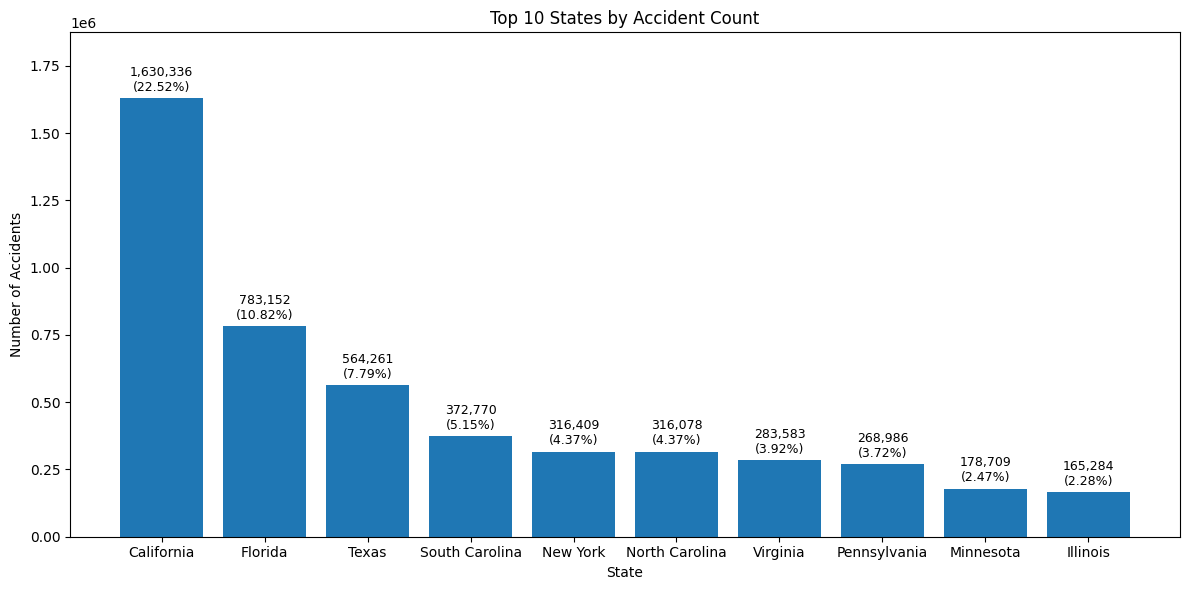

In [ ]:
# ── Top 10 States by Accident Count ──────────────────────────────────────────
top10_states = df['State'].value_counts().head(10)
percentages = (top10_states / len(df) * 100).round(2)

fig, ax = plt.subplots(figsize=(12, 6))
bars = ax.bar(top10_states.index.map(STATE_NAMES), top10_states.values)

for bar, count, pct in zip(bars, top10_states.values, percentages):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + top10_states.values.max() * 0.01,
            f'{count:,}\n({pct}%)', ha='center', va='bottom', fontsize=9)

ax.set_title('Top 10 States by Accident Count')
ax.set_xlabel('State')
ax.set_ylabel('Number of Accidents')
ax.set_ylim(0, top10_states.values.max() * 1.15)
plt.tight_layout()
plt.show()

The high accident counts are largely a function of population and traffic
volume rather than particularly dangerous driving conditions.

California, Texas, and Florida are the three most populous states in the US. This explains why they appear on top.

However, South Carolina ranks around the 23rd country in population which is surprising. So we checked and according to reports, the state ranks as the 2nd highest state in terms of car accidents per 100,000 residents ([Link](https://www.ctbrookslaw.com/blog/south-carolina-car-accident-statistics/)).

/tmp/ipykernel_4700/152420503.py:5: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  city_state = df.groupby('City')['State'].agg(lambda x: x.mode()[0])
/tmp/ipykernel_4700/152420503.py:16: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels([f'{city}\n({city_state[city]})' for city in top10_cities.index], rotation=45, ha='right')


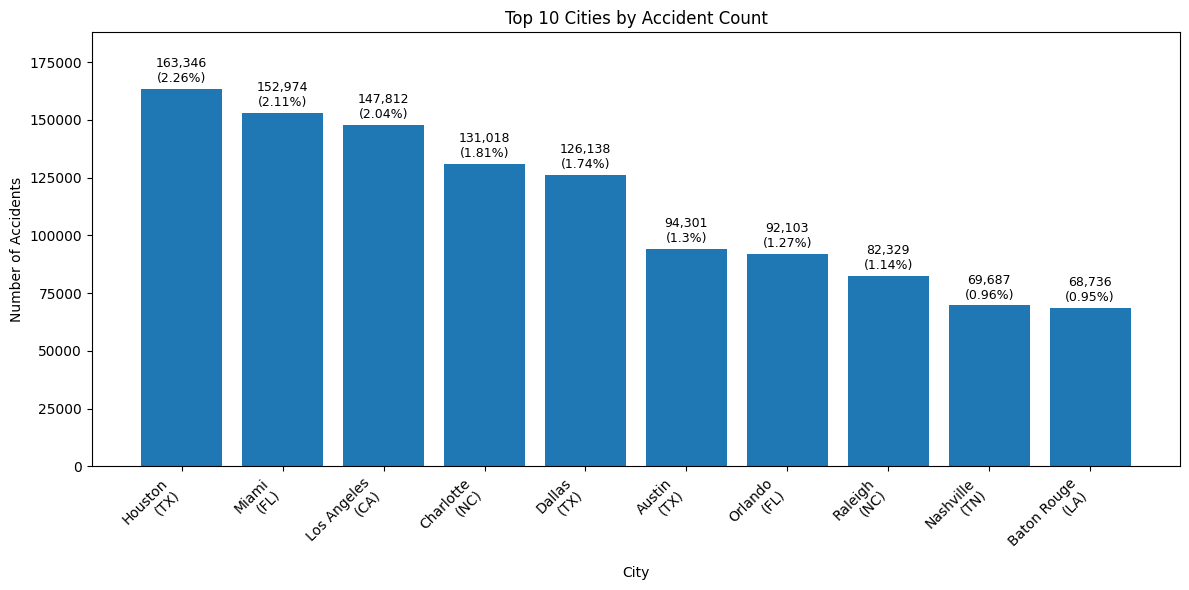

In [ ]:
# ── Top 10 Cities by Accident Count ──────────────────────────────────────────
top10_cities = df['City'].value_counts().head(10)
percentages = (top10_cities / len(df) * 100).round(2)

city_state = df.groupby('City')['State'].agg(lambda x: x.mode()[0])
fig, ax = plt.subplots(figsize=(12, 6))
bars = ax.bar(top10_cities.index, top10_cities.values)

for bar, count, pct in zip(bars, top10_cities.values, percentages):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + top10_cities.values.max() * 0.01,
            f'{count:,}\n({pct}%)', ha='center', va='bottom', fontsize=9)

ax.set_title('Top 10 Cities by Accident Count')
ax.set_xlabel('City')
ax.set_ylabel('Number of Accidents')
ax.set_xticklabels([f'{city}\n({city_state[city]})' for city in top10_cities.index], rotation=45, ha='right')
ax.set_ylim(0, top10_cities.values.max() * 1.15)
plt.tight_layout()
plt.show()

The cities that do appear are largely from the most populous states - Houston, Dallas, and Austin representing Texas, Miami and Orlando representing Florida, and Los Angeles representing California.

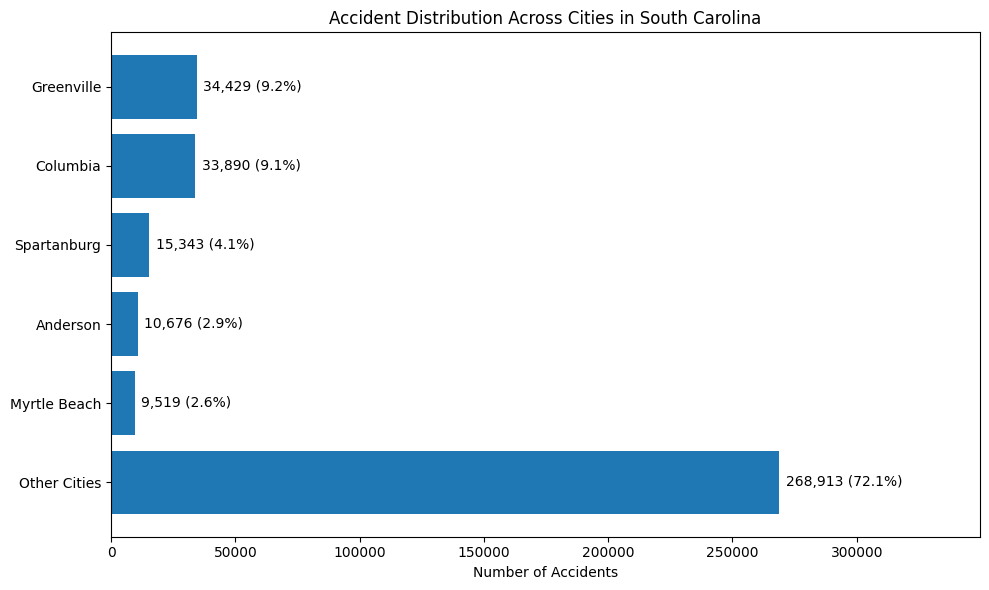

In [ ]:
state, state_name = 'SC', 'South Carolina'
state_cities = df[df['State'] == state]['City'].value_counts().head(5)
state_total = len(df[df['State'] == state])
state_other = state_total - state_cities.sum()

state_plot = pd.concat([state_cities, pd.Series({'Other Cities': state_other})])

fig, ax = plt.subplots(figsize=(10, 6))
bars = ax.barh(state_plot.index[::-1], state_plot.values[::-1])

for bar, count in zip(bars, state_plot.values[::-1]):
    ax.text(bar.get_width() + state_plot.values.max() * 0.01, bar.get_y() + bar.get_height() / 2,
            f'{count:,} ({count/state_total*100:.1f}%)', va='center', fontsize=10)

ax.set_title(f'Accident Distribution Across Cities in {state_name}')
ax.set_xlabel('Number of Accidents')
ax.set_xlim(0, state_plot.values.max() * 1.3)
plt.tight_layout()
plt.show()

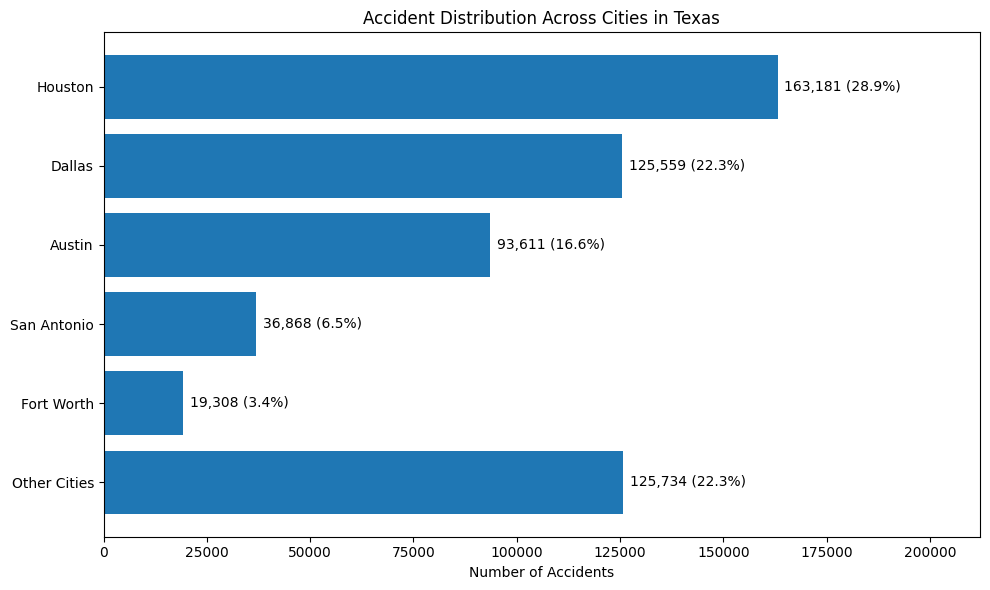

In [ ]:
state, state_name = 'TX', 'Texas'
state_cities = df[df['State'] == state]['City'].value_counts().head(5)
state_total = len(df[df['State'] == state])
state_other = state_total - state_cities.sum()

state_plot = pd.concat([state_cities, pd.Series({'Other Cities': state_other})])

fig, ax = plt.subplots(figsize=(10, 6))
bars = ax.barh(state_plot.index[::-1], state_plot.values[::-1])

for bar, count in zip(bars, state_plot.values[::-1]):
    ax.text(bar.get_width() + state_plot.values.max() * 0.01, bar.get_y() + bar.get_height() / 2,
            f'{count:,} ({count/state_total*100:.1f}%)', va='center', fontsize=10)

ax.set_title(f'Accident Distribution Across Cities in {state_name}')
ax.set_xlabel('Number of Accidents')
ax.set_xlim(0, state_plot.values.max() * 1.3)
plt.tight_layout()
plt.show()

These plots highlights a clear contrast - Texas's high accident count is largely explained by having three of the largest cities in the US driving the numbers, while South Carolina's accidents are spread across smaller cities. Combined with external reports confirming SC ranks 2nd in accidents per 100,000 residents, this suggests a statewide road safety issue.

**Conclusion 1**

Road accidents in the US show a clear and serious upward trend. The most affected regions are the most populated ones, but it's worth noting that population alone does not tell the whole story since some of the states point to deeper road safety issues.

### Can Accident Hotspots Reveal Infrastructure Failures That Put Drivers at Risk?

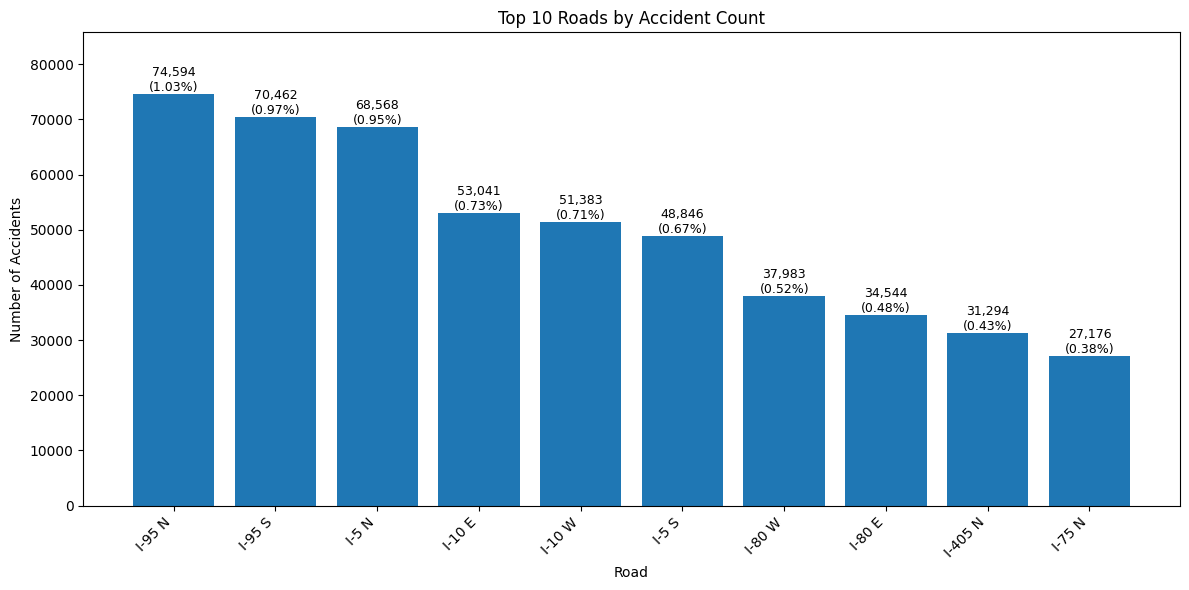

In [ ]:
# ── Top 10 Roads by Accident Count ──────────────────────────────────────────
top10_roads = df['Road'].value_counts().head(10)
percentages = (top10_roads / len(df) * 100).round(2)

fig, ax = plt.subplots(figsize=(12, 6))
bars = ax.bar(top10_roads.index, top10_roads.values)

for bar, count, pct in zip(bars, top10_roads.values, percentages):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height(),
            f'{count:,}\n({pct}%)', ha='center', va='bottom', fontsize=9)

ax.set_title('Top 10 Roads by Accident Count')
ax.set_xlabel('Road')
ax.set_ylabel('Number of Accidents')
ax.set_ylim(0, top10_roads.values.max() * 1.15)
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

I-95 leads the list - this is in fact not surprising, as according to multiple reports it is the deadliest interstate in the US:

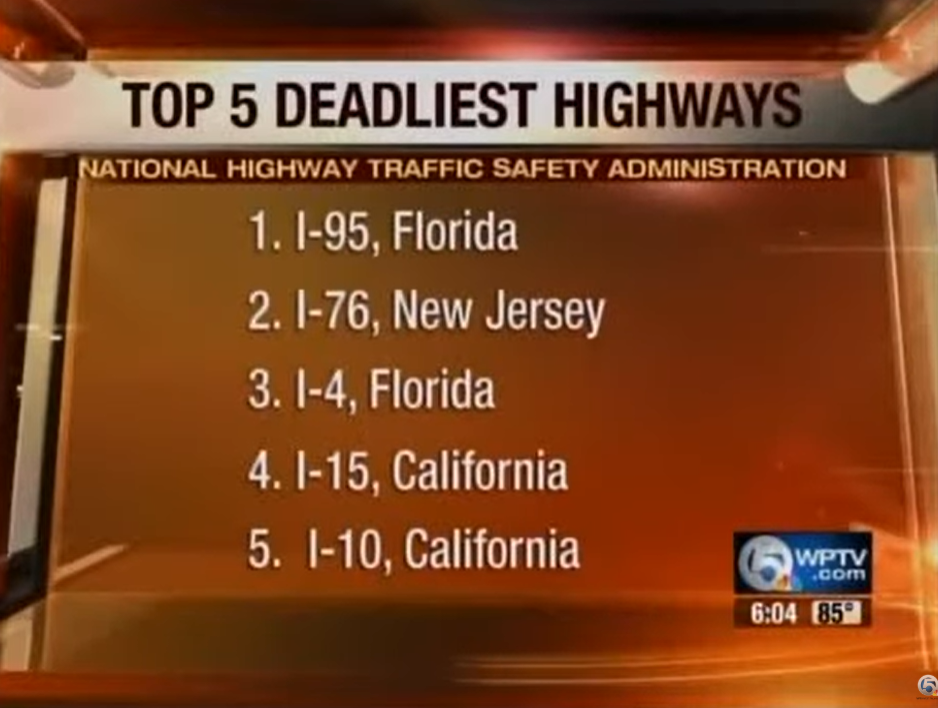

At first glance, interstates dominate the top 10 most accident-prone roads. But does this mean interstates are the most dangerous road type overall? We will look at the bigger picture.

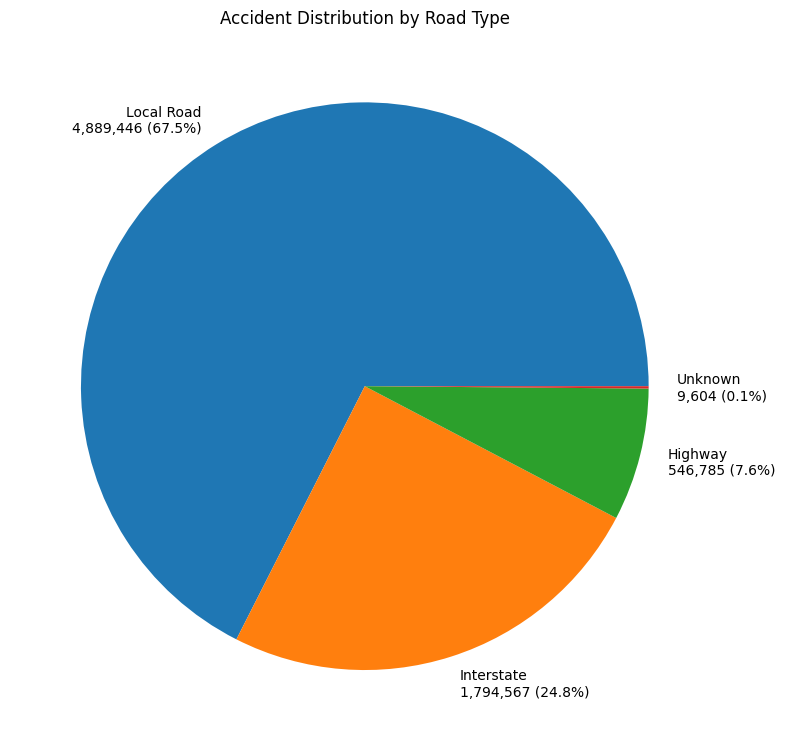

In [ ]:
# ── Road Type Distribution ───────────────────────────────────────────────────
road_type_counts = df['Road_Type'].astype(object).fillna('Unknown').value_counts()
labels = [f'{rt}\n{count:,} ({count/len(df)*100:.1f}%)'
          for rt, count in zip(road_type_counts.index, road_type_counts.values)]

fig, ax = plt.subplots(figsize=(8, 8))
ax.pie(road_type_counts.values, labels=labels, autopct='')
ax.set_title('Accident Distribution by Road Type')
plt.tight_layout()
plt.show()

Local roads account for the majority of accidents, which may seem counterintuitive given that they have lower speed limits than highways. A likely explanation is that drivers are less alert on familiar roads near their homes, developing a false sense of security that leads to less cautious driving. Additionally, local roads are inherently more complex environments - packed with traffic signals and junctions. We'll examine this more closely in the next plot.

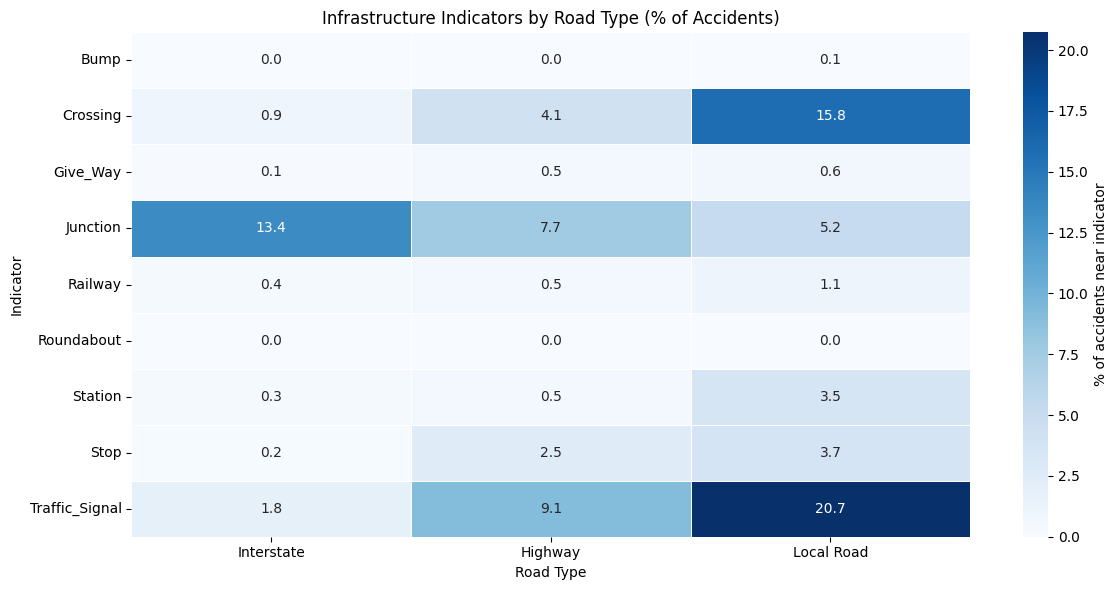

In [ ]:
# Boolean infrastructure indicators
INDICATORS = ['Bump', 'Crossing', 'Give_Way', 'Junction', 'Railway',
              'Roundabout', 'Station', 'Stop', 'Traffic_Signal']

# Calculate percentage of accidents with each indicator True, per road type
indicator_data = (
    df[df['Road_Type'].notna()]
    .groupby('Road_Type', observed=True)[INDICATORS]
    .mean() * 100
).reindex(['Interstate', 'Highway', 'Local Road'])

fig, ax = plt.subplots(figsize=(12, 6))
sns.heatmap(
    indicator_data.T,
    annot=True,
    fmt='.1f',
    cmap='Blues',
    linewidths=0.5,
    ax=ax,
    cbar_kws={'label': '% of accidents near indicator'}
)
ax.set_title('Infrastructure Indicators by Road Type (% of Accidents)')
ax.set_xlabel('Road Type')
ax.set_ylabel('Indicator')
plt.tight_layout()
plt.show()

This confirms that the infrastructure creates the risk - accidents happen where the road forces interactions between vehicles, pedestrians, and decisions. Each road type has its own distinct danger profile: interstates concentrate risk at merges, while local roads see accidents cluster around traffic signals and crossings.

Notably, roundabouts show 0%, because they are extremely rare in the US compared to other countries. Also, roundabouts are known to eliminate the most dangerous conflict points that junctions create, by forcing all vehicles to reduce speed.

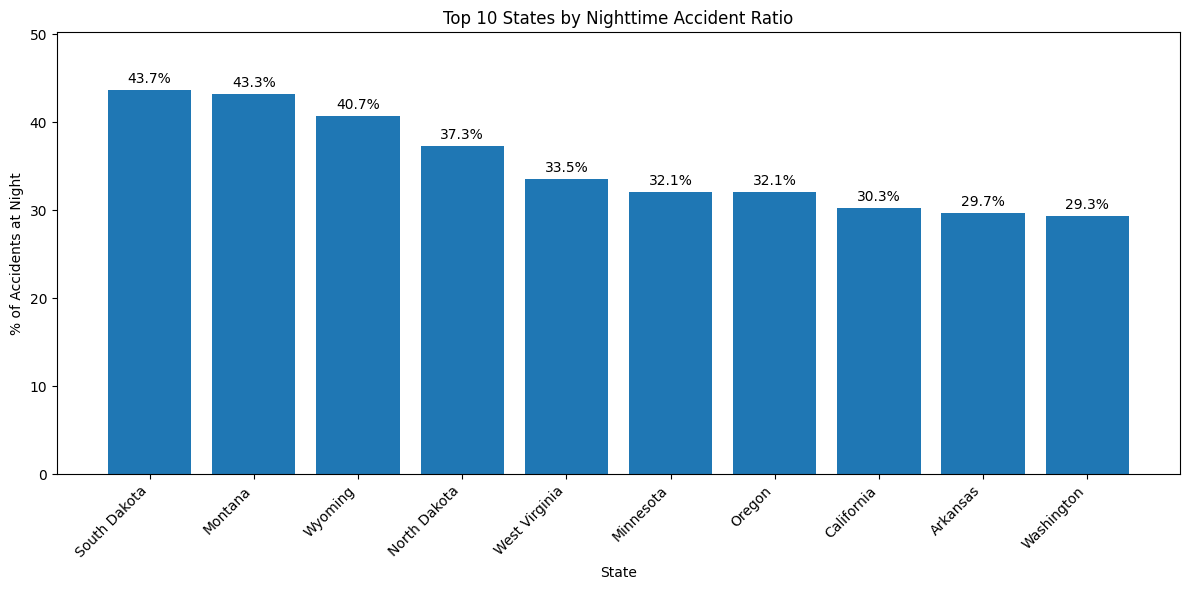

In [ ]:
# Top 10 states by nighttime accident ratio
total_by_state = df.groupby('State', observed=True).size()
night_by_state = df[df['Is_Day'] == False].groupby('State', observed=True).size()

night_ratio_state = (night_by_state / total_by_state * 100).dropna().sort_values(ascending=False).head(10)

fig, ax = plt.subplots(figsize=(12, 6))
bars = ax.bar(night_ratio_state.index.map(STATE_NAMES), night_ratio_state.values)

for bar, pct in zip(bars, night_ratio_state.values):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + night_ratio_state.values.max() * 0.01,
            f'{pct:.1f}%', ha='center', va='bottom', fontsize=10)

ax.set_title('Top 10 States by Nighttime Accident Ratio')
ax.set_xlabel('State')
ax.set_ylabel('% of Accidents at Night')
ax.set_ylim(0, night_ratio_state.values.max() * 1.15)
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

Rural states like South Dakota, Montana, and Wyoming face a disproportionately high risk of severe nighttime crashes. These states are characterized by long roads, vast distances between towns, and high wildlife populations. While we cannot confirm the exact cause from this dataset alone, poor road lighting combined with these environmental factors appears to be a likely contributing factor.

**Conclusion 2**

While drivers remain the primary cause of accidents, infrastructure creates the conditions for risk. We assume smarter infrastructure design could reduce the opportunity for human error to turn into tragedy.

### Can Accident Patterns Reveal Underlying Safety Issues and Guide Smarter Deployment of Emergency Services?

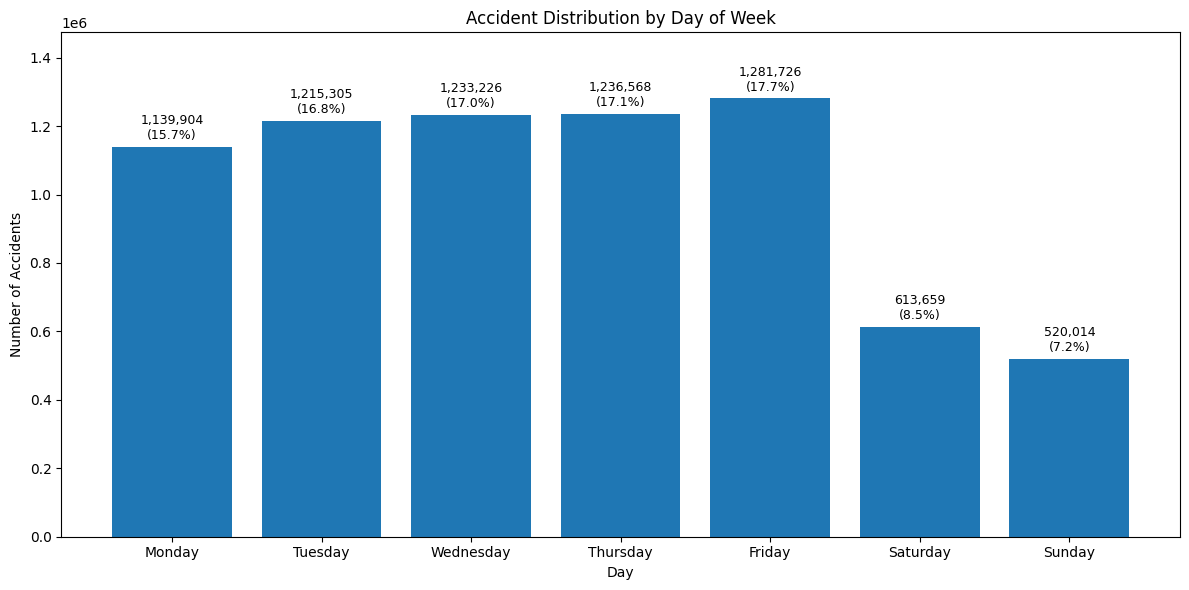

In [ ]:
# ── Accidents by Day of Week ──────────────────────────────────────────────────
day_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
day_counts = df['Datetime'].dt.day_name().value_counts().reindex(day_order)
total = len(df)

fig, ax = plt.subplots(figsize=(12, 6))
bars = ax.bar(day_counts.index, day_counts.values)

for bar, count in zip(bars, day_counts.values):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + day_counts.values.max() * 0.01,
            f'{count:,}\n({count/total*100:.1f}%)', ha='center', va='bottom', fontsize=9)

ax.set_title('Accident Distribution by Day of Week')
ax.set_xlabel('Day')
ax.set_ylabel('Number of Accidents')
ax.set_ylim(0, day_counts.values.max() * 1.15)
plt.tight_layout()
plt.show()

Weekdays account for the vast majority of accidents.

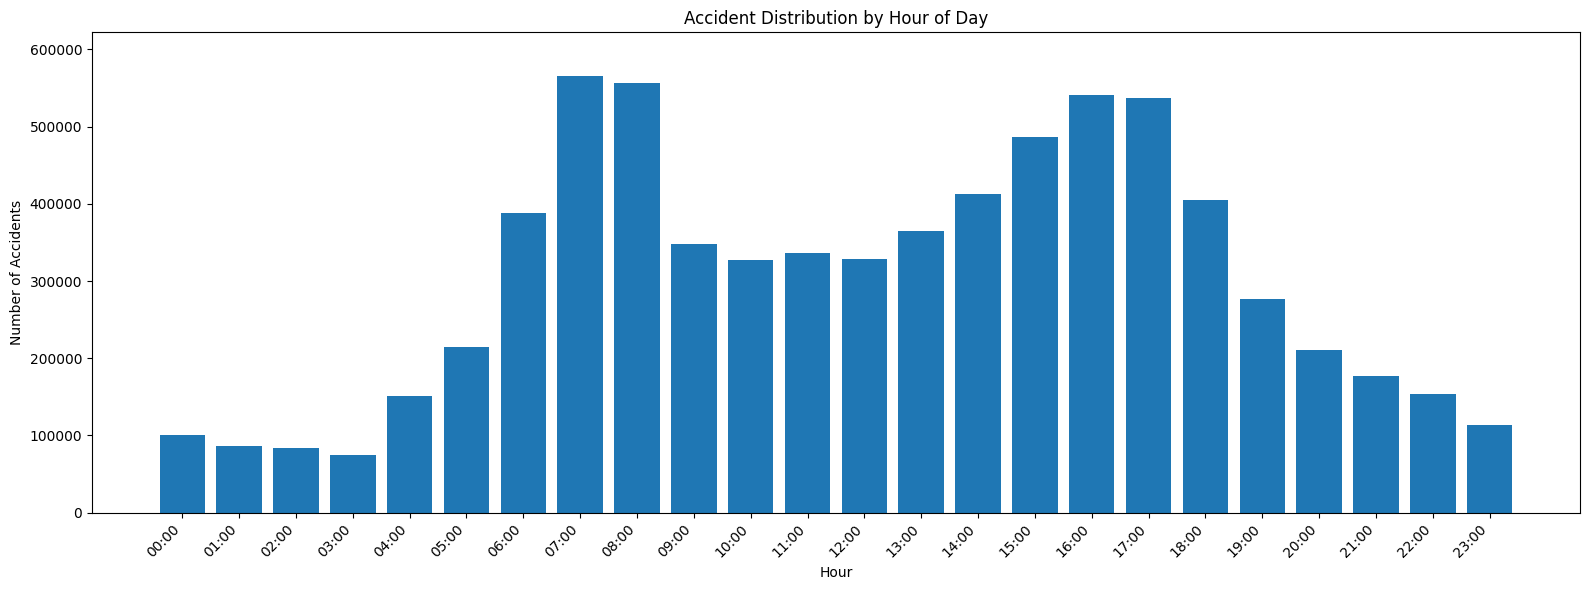

In [ ]:
# ── Accidents by Hour of Day ──────────────────────────────────────────────────
hour_counts = df['Datetime'].dt.hour.value_counts().sort_index()
hour_labels = [f'{h:02d}:00' for h in range(24)]

fig, ax = plt.subplots(figsize=(16, 6))
ax.bar(hour_labels, hour_counts.values)

ax.set_title('Accident Distribution by Hour of Day')
ax.set_xlabel('Hour')
ax.set_ylabel('Number of Accidents')
ax.set_ylim(0, hour_counts.values.max() * 1.1)
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

The hourly distribution clearly reflects commuting patterns - two distinct peaks emerge at 07:00–08:00 (morning rush hour) and 16:00–17:00 (evening rush hour). The late night hours (00:00–03:00) show the lowest accident counts, which makes sense as fewer people are on the road.

Both plots confirm that accident frequency is primarily driven by traffic volume. The more cars on the road, the more accidents occur.

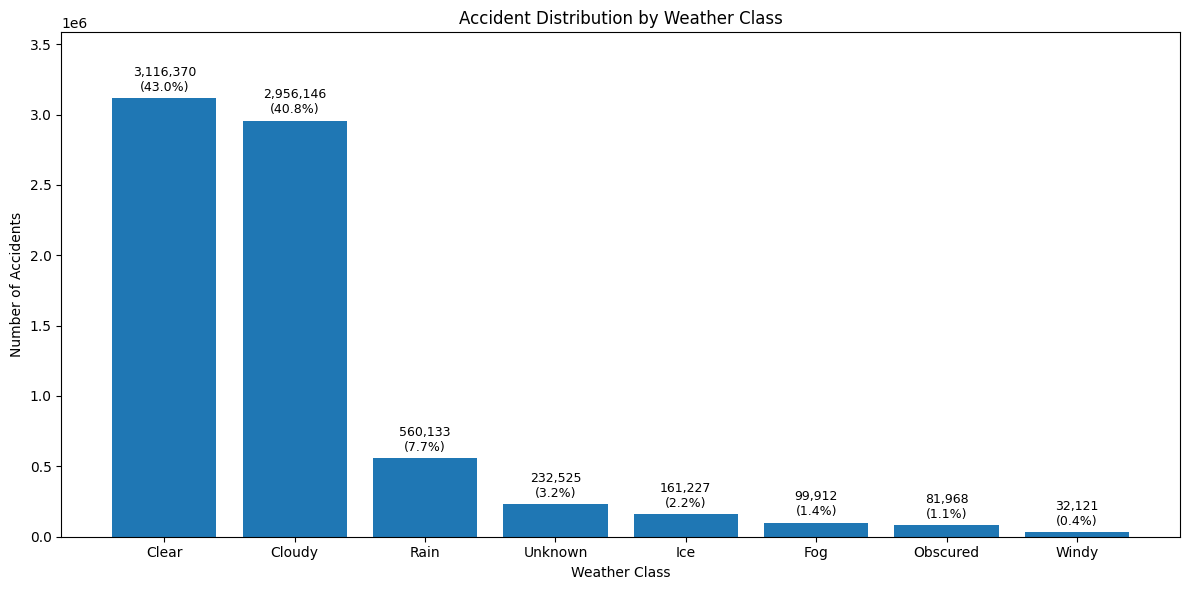

In [ ]:
# ── Accidents by Weather Class ────────────────────────────────────────────────
weather_counts = df['Weather_Class'].astype(object).fillna('Unknown').value_counts()
total = len(df)

fig, ax = plt.subplots(figsize=(12, 6))
bars = ax.bar([cls.title() for cls in weather_counts.index], weather_counts.values)

for bar, count in zip(bars, weather_counts.values):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + weather_counts.values.max() * 0.01,
            f'{count:,}\n({count/total*100:.1f}%)', ha='center', va='bottom', fontsize=9)

ax.set_title('Accident Distribution by Weather Class')
ax.set_xlabel('Weather Class')
ax.set_ylabel('Number of Accidents')
ax.set_ylim(0, weather_counts.values.max() * 1.15)
plt.tight_layout()
plt.show()

We assume most driving happens in clear weather, and for that reason most accidents happen there too. To know whether rain or ice is truly more dangerous, we would need to normalize by how often each weather condition actually occurs - for example, comparing the percentage of accidents in rain against the percentage of days it actually rained throughout the year. Without external weather frequency data, we cannot make this comparison from this dataset alone.

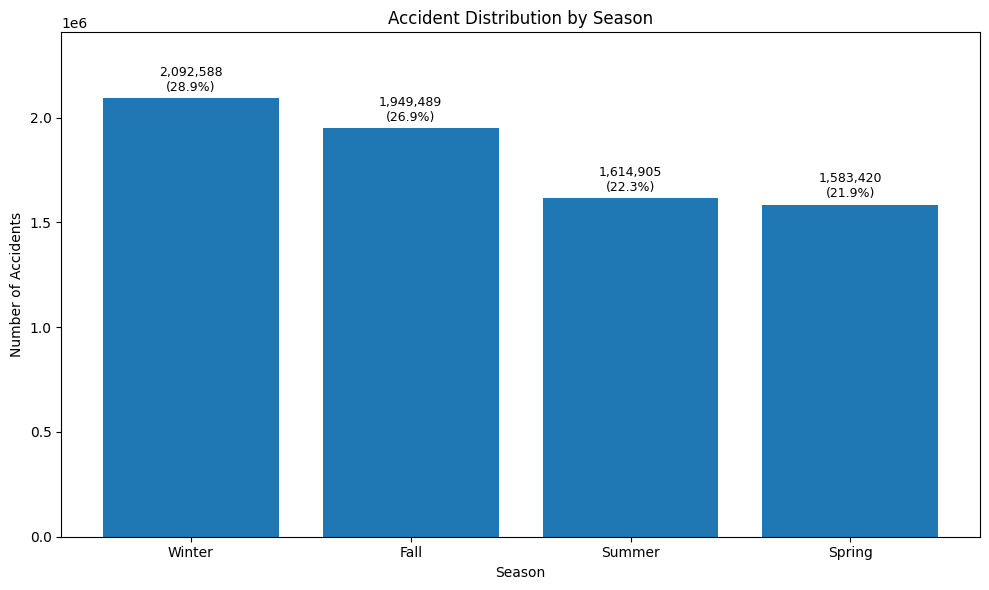

In [ ]:
# ── Accidents by Season ───────────────────────────────────────────
season_counts = df['Season'].value_counts()
total = len(df)

fig, ax = plt.subplots(figsize=(10, 6))
bars = ax.bar(season_counts.index, season_counts.values)

for bar, count in zip(bars, season_counts.values):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + season_counts.values.max() * 0.01,
            f'{count:,}\n({count/total*100:.1f}%)', ha='center', va='bottom', fontsize=9)

ax.set_title('Accident Distribution by Season')
ax.set_xlabel('Season')
ax.set_ylabel('Number of Accidents')
ax.set_ylim(0, season_counts.values.max() * 1.15)
plt.tight_layout()
plt.show()

Interestingly, this pattern is not explained by adverse weather conditions - as we saw earlier, the vast majority of accidents happen in clear or cloudy weather regardless of season. A more likely explanation is that winter and fall have significantly shorter daylight hours, meaning more driving happens in the dark. We will check if the data supports this.

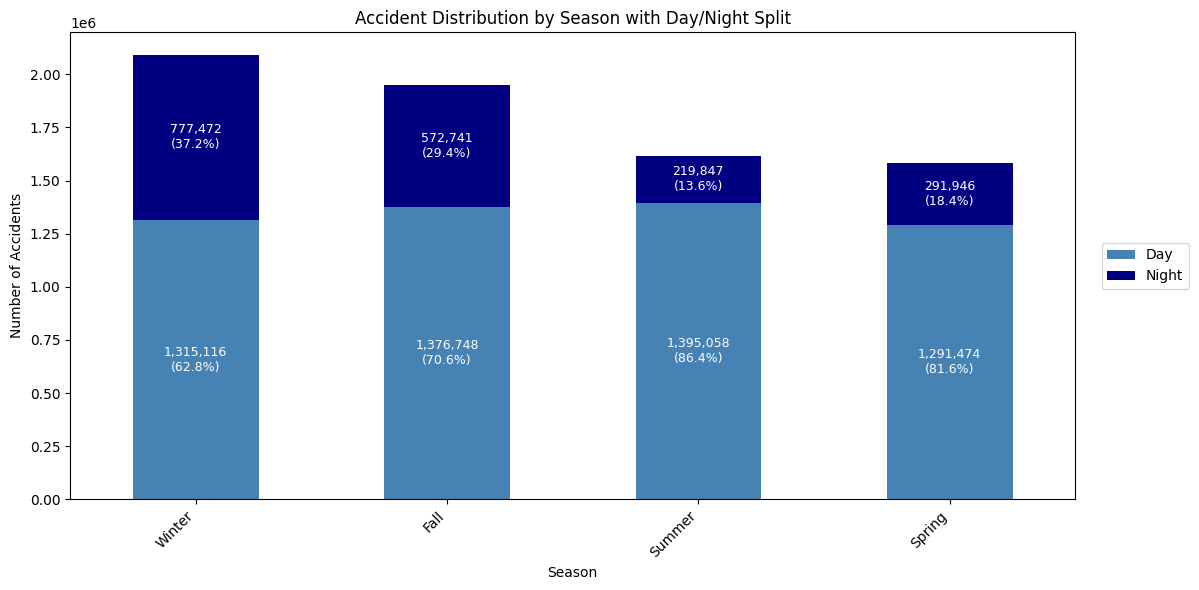

In [ ]:
# ── Accidents by Season with Day/Night Split ──────────────────────────────────
day_night_counts = (
    df[df['Is_Day'].notna()]
    .groupby(['Season', 'Is_Day'], observed=True)
    .size()
    .unstack()
)
day_night_counts.columns = ['Night', 'Day']
day_night_counts = day_night_counts.reindex(['Winter', 'Fall', 'Summer', 'Spring'])

fig, ax = plt.subplots(figsize=(12, 6))
day_night_counts[['Day', 'Night']].plot(kind='bar', stacked=True, ax=ax, color=['steelblue', 'navy'])

total_by_season = day_night_counts.sum(axis=1)
for i, (idx, row) in enumerate(day_night_counts.iterrows()):
    ax.text(i, row['Day'] / 2, f"{row['Day']:,}\n({row['Day']/total_by_season[idx]*100:.1f}%)",
            ha='center', va='center', color='white', fontsize=9)
    ax.text(i, row['Day'] + row['Night'] / 2, f"{row['Night']:,}\n({row['Night']/total_by_season[idx]*100:.1f}%)",
            ha='center', va='center', color='white', fontsize=9)

ax.set_title('Accident Distribution by Season with Day/Night Split')
ax.set_xlabel('Season')
ax.set_ylabel('Number of Accidents')
ax.legend(loc='center right', bbox_to_anchor=(1.12, 0.5))
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

The daytime accident counts are remarkably similar across all seasons. The key difference is the nighttime portion: winter accounts for 37.2% nighttime accidents compared to only 13.6% in summer. The additional winter accidents are driven almost entirely by increased driving in the dark - directly suggesting that shorter daylight hours are a primary contributor to winter's higher accident count.

In [ ]:
# ── Day vs Night by Weekday/Weekend ──────────────────────────────────────────
df_daynight = df[df['Is_Day'].notna()].copy()
df_daynight['Is_Weekend'] = df_daynight['Datetime'].dt.dayofweek >= 4  # 4=Friday, 5=Saturday, 6=Sunday

day_night_wk = (
    df_daynight.groupby('Is_Weekend', observed=True)['Is_Day']
    .value_counts(normalize=True)
    .unstack() * 100
)
day_night_wk.columns = ['Night', 'Day']
day_night_wk.index = ['Weekday (Mon–Thu)', 'Weekend (Fri–Sun)']

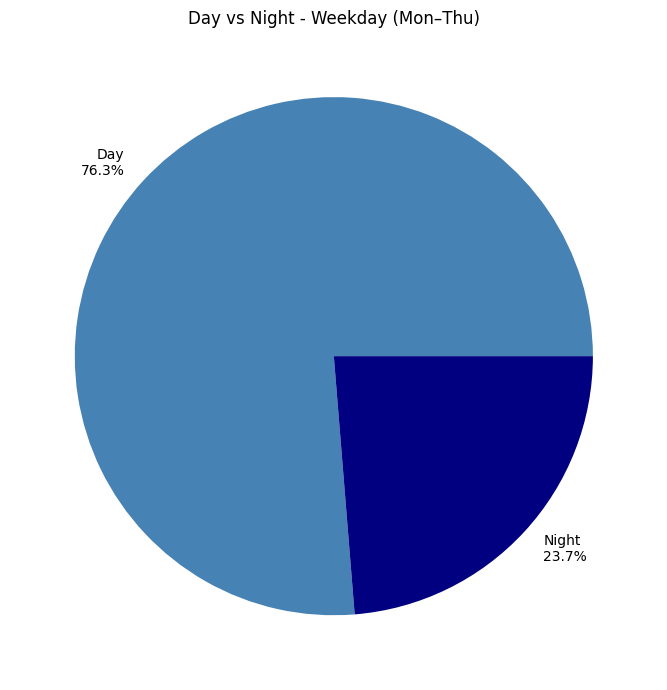

In [ ]:
fig, ax = plt.subplots(figsize=(7, 7))
row = day_night_wk.loc['Weekday (Mon–Thu)']
ax.pie([row['Day'], row['Night']],
       labels=[f"Day\n{row['Day']:.1f}%", f"Night\n{row['Night']:.1f}%"],
       colors=['steelblue', 'navy'])
ax.set_title('Day vs Night - Weekday (Mon–Thu)')
plt.tight_layout()
plt.show()

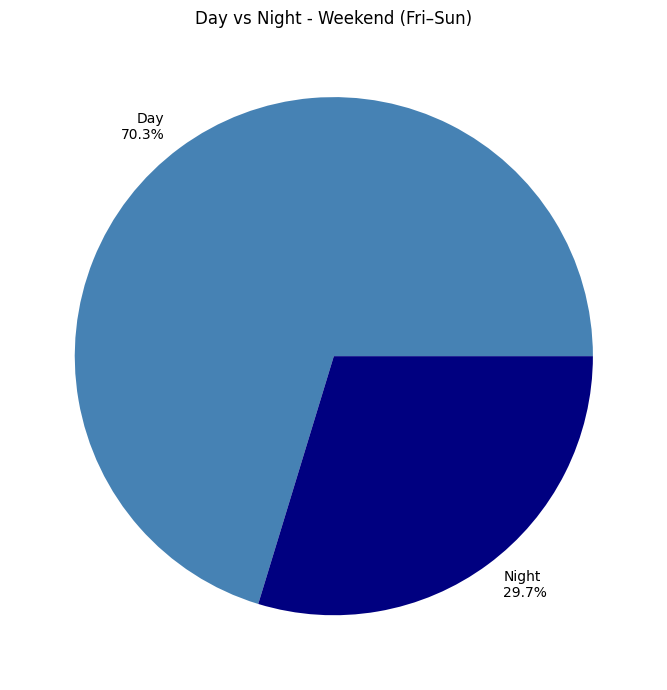

In [ ]:
fig, ax = plt.subplots(figsize=(7, 7))
row = day_night_wk.loc['Weekend (Fri–Sun)']
ax.pie([row['Day'], row['Night']],
       labels=[f"Day\n{row['Day']:.1f}%", f"Night\n{row['Night']:.1f}%"],
       colors=['steelblue', 'navy'])
ax.set_title('Day vs Night - Weekend (Fri–Sun)')
plt.tight_layout()
plt.show()

Weekends (Friday–Sunday) show a slightly higher nighttime accident proportion (29.7%) compared to weekdays (23.7%). This is consistent with more late-night activity on weekends.

**Conclusion 3**

Accident patterns closely mirror human activity - peaking during rush hours, on weekdays, and in winter when daylight is limited. Weather appears less decisive than might be expected. Overall, the data suggests that when people drive matters more than the conditions they drive in. Therefore, emergency services should prioritize greater coverage to handle incidents and stronger enforcement to prevent them, particularly during peak commuting hours.

### Where Should Accident Prevention Efforts Be Focused?

Text(95.72222222222221, 0.5, 'Traffic Impact')

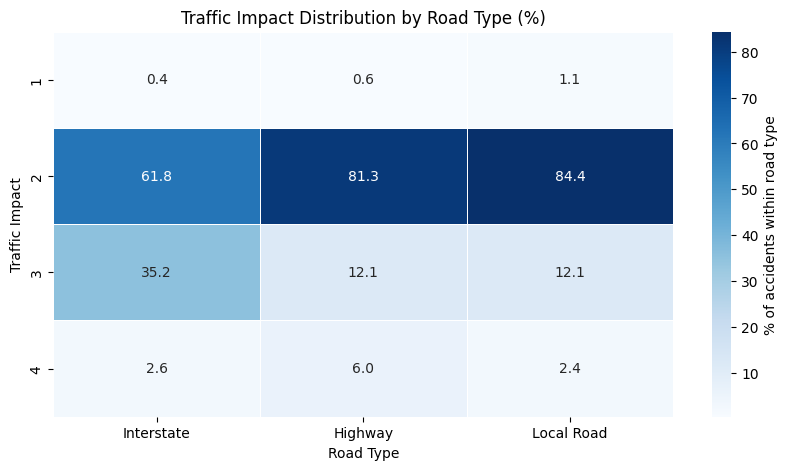

In [ ]:
# ── Traffic Impact by Road Type (Normalized Heatmap) ────────────────────────
heatmap_data = (
    df.groupby(['Road_Type', 'Traffic_Impact'], observed=True)
    .size()
    .unstack(fill_value=0)
)

# Normalize within each road type so rows sum to 100%
heatmap_pct = heatmap_data.div(heatmap_data.sum(axis=1), axis=0) * 100
heatmap_pct = heatmap_pct.reindex(['Interstate', 'Highway', 'Local Road'])

fig, ax = plt.subplots(figsize=(10, 5))
sns.heatmap(
    heatmap_pct.T,
    annot=True,
    fmt='.1f',
    cmap='Blues',
    linewidths=0.5,
    ax=ax,
    cbar_kws={'label': '% of accidents within road type'}
)
ax.set_title('Traffic Impact Distribution by Road Type (%)')
ax.set_xlabel('Road Type')
ax.set_ylabel('Traffic Impact')

The vast majority of accidents across all road types fall into Impact 2, meaning most accidents cause moderate but not severe traffic disruption.

The most notable difference is in the higher impacts - interstates show higher impacts compared to highways and local roads. We assume that the reason the are almost not exits on these roads, even if the accident itself isn't catastrophic.
Local roads and highways, on the other hand, offer more alternative routes.

As mentioned earlier, interstates are the deadliest. When accidents occur at high speeds, the severity increases - meaning longer response times, more lanes blocked, and ultimately greater traffic disruption.

**Conclusion 4**

Although most accidents occur on local roads, prevention efforts should prioritize interstates and highways - where accidents are fewer but can be more disruptive and severe.